# 12 — Combined clean evaluation: metadata uncertainty, cutoffs and calibration: deduplicated Subset data

Do the network's scores clearly improve on the spline? Do predicted risks match observed rates, and how much review work follows a cutoff aimed at finding 80% of malignant images?

[07_metadata_tuning.ipynb](07_metadata_tuning.ipynb) retains the fixed spline. We read the network predictions from [06_metadata_neural_network.ipynb](06_metadata_neural_network.ipynb) and assess that choice using metadata, the information alongside each image.

The saved run gives no clear average precision (AP) improvement from the network. The training-selected cutoff finds 80.3% of held-out malignant images while flagging 68.6% of all images. The reserved test labels are not used.

For metric definitions, see the [short concept guide](../concepts.md).


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [08_metadata_robustness.ipynb](../Subset/08_metadata_robustness.ipynb).

The clean workflow's primary ranking measure is **unweighted mean outer-fold AP**. Original figure composition and colour meanings are retained. The paired interval plot explicitly displays mean-fold AP, while pooled values remain secondary tables; their values are not interchangeable.

## Context and methods

### Separate choosing a rule from assessing it

A fold is a group of patients; all their images stay together. For each of five outer folds:

1. Reserve its patients for assessment.
2. Within the four training folds, fit on three and predict the fourth, four times. These inner out-of-fold (OOF) scores are made without training on the scored patient.
3. Use only inner scores and labels for recalibration and cutoff selection.
4. Fit the spline on all four training folds, predict the outer patients, and assess the chosen rules there. Combine the five outer tables.

Recalibration is a logistic adjustment to the level and spread of probability estimates. Its settings are fixed, rather than chosen from outer results. Calibration asks whether estimates such as 3% agree with observed malignant rates among comparable cases. A score in [0,1] does not establish that agreement.

The cutoff is the score at or above which an image is flagged. Choose the highest inner cutoff meeting 80% recall, the share of malignant images found. This is an academic scenario; outer recall may be lower. Preprocessing is fitted entirely within training, and explicit checks enforce patient separation.

### Read performance and uncertainty together

Average precision (AP) is the primary ranking measure: higher means malignant images concentrate nearer the top. ROC-AUC measures how often a malignant image scores above a benign one; 0.5 is chance. Log loss and Brier score measure probability error; lower is better.

For uncertainty, bootstrap whole patients: repeatedly sample patients with replacement separately within each original outer fold, keeping their images together. The middle 95% of resampled results forms an interval. Compare methods on the same draws to estimate their difference. These intervals keep saved predictions fixed, without retraining.

Results are per image, so patients with more images carry more weight. The reused folds have guided earlier choices; these checks cannot make the comparison an independent final test. The completed clean fits and training-selected cutoffs are already fingerprinted. **Scope qualification:** the original notebook also fitted a final all-development bundle. This report defers that separate clean fit until modelling choices are settled; the historical bundle remains preserved.


### 1. Set up the run

Use the saved three-run network predictions from notebook 06 with `requirements-metadata.txt` and the project Python kernel. The next checks verify their data, code and prediction fingerprints before comparison. Re-executing later cells refits metadata models and replaces their named development outputs.


In [1]:
NOTEBOOK_STAGE = '12_combined_evaluation'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay, average_precision_score,
    balanced_accuracy_score, brier_score_loss, confusion_matrix, log_loss,
    roc_auc_score, roc_curve, precision_recall_curve,
)
from melanoma_detection.metadata_evaluation import probability_metrics, decision_metrics, calibration_bins
from melanoma_detection.dedup_notebook_metadata import (
    saved_metadata, metric_table, exploratory_cutoff, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
from melanoma_detection.dedup_notebook_metadata_templates import marginal_age_profile, metadata_patient_intervals
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
PROJECT_ROOT = ROOT
train = bundle["frame"].set_index("image_name").loc[frame.image_id].reset_index()
assert np.array_equal(train.patient_id, frame.patient_id)
assert np.array_equal(train.target, frame.target)
assert np.array_equal(train.fold, frame.fold)
assert train.groupby("patient_id").fold.nunique().eq(1).all()
assert train.image_name.is_unique and len(train) == 6706
assert int(train.target.sum()) == 127
FEATURE_COLUMNS = ["sex", "age_approx", "anatom_site_general_challenge"]
FEATURES = FEATURE_COLUMNS
DATA_PATH = ROOT / "data/subset/processed/dedup_v1/dataset_manifest.json"
TRAIN_FOLDS_PATH = DATA_PATH
REPORT_DIR = ROOT / "results/dedup_v1/clean_workflow/metadata_depth" / NOTEBOOK_STAGE
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = FIGURE_DIR
TABLES = METRICS = PREDICTIONS = REPORT_DIR
plt.rcdefaults()

TARGET_RECALL = .80
BOOTSTRAP_REPETITIONS, BOOTSTRAP_SEED = 2000, 42


# Preserve the original notebook's plotting defaults.
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
ORIGINAL_EXPORT_DPI = 180


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## Data

### 2. Check inputs and match images

Match predictions by image name and verify patient IDs, labels and folds. Check data, prediction and validation-code fingerprints; the clean manifest and retained-record identity must match both metadata receipts. This prevents comparisons with another dataset or changed method. The table confirms the development population.


In [2]:

print(f"Manifest: {DATA_PATH.relative_to(ROOT)}")
print(f"Dataset identity: {bundle['identity']['dataset_identity']}")
print(f"Images: {len(train):,}; patients: {train.patient_id.nunique():,}")
print(f"Malignant images: {int(train.target.sum()):,} ({train.target.mean():.2%})")
print(f"Malignant patients: {train.loc[train.target.eq(1), 'patient_id'].nunique():,}")
print("Original patient folds retained; reserved test not loaded.")

nn_predictions = pd.read_csv(meta["base"] / "metadata_nn_oof.csv")
nn_predictions = nn_predictions.set_index("image_name").loc[train.image_name].reset_index()
for column in ["patient_id", "target", "fold"]:
    assert np.array_equal(train[column], nn_predictions[column])
display(pd.DataFrame([{"Images": len(train), "Patients": train.patient_id.nunique(),
    "Malignant images": int(train.target.sum()), "Patients with malignancy": train.loc[train.target.eq(1), "patient_id"].nunique(),
    "Malignant image fraction": train.target.mean()}]).round(4))


Manifest: data\subset\processed\dedup_v1\dataset_manifest.json
Dataset identity: 0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae9f9eb7e57825b04af1
Images: 6,706; patients: 422
Malignant images: 127 (1.89%)
Malignant patients: 88
Original patient folds retained; reserved test not loaded.


,Images,Patients,Malignant images,Patients with malignancy,Malignant image fraction
0,6706,422,127,88,0.0189


## Results

### 3. Verify calibration and cutoffs selected using training patients

The raw spline keeps four cubic age knots and regularisation C=1. For every outer fold, only the inner training scores supply information for recalibration and cutoff selection. The saved audit table records the size and class counts of each partition.

The table below shows each training-selected cutoff beside its results on outer patients. Compare sensitivity (malignant images found), specificity (benign images left unflagged), precision (malignancy among flagged images) and the fraction flagged. These columns show why meeting a recall target can require many false alarms.


In [3]:

outer_predictions = meta["calibration"].copy()
split_audit = pd.read_csv(meta["base"] / "spline_inner_audit.csv")
assert split_audit.patient_overlap.eq(0).all()
np.testing.assert_allclose(outer_predictions.p_spline_raw, scores["spline_raw"], rtol=0, atol=1e-14)
fold_rows = []
for fold, rows in outer_predictions.groupby("fold"):
    for version, p_column, decision_column, threshold_column in [
        ("Raw spline", "p_spline_raw", "decision_raw", "raw_threshold"),
        ("Recalibrated spline", "p_spline_calibrated", "decision_calibrated", "calibrated_threshold")]:
        fold_rows.append({"fold": fold, "procedure": version, "training_selected_threshold": rows[threshold_column].iloc[0],
            **probability_metrics(rows.target, rows[p_column]), **decision_metrics(rows.target, rows[decision_column])})
fold_metrics = pd.DataFrame(fold_rows)
display(split_audit.round(5))
display(fold_metrics[["fold", "procedure", "training_selected_threshold", "sensitivity", "specificity", "precision", "flagged_fraction"]].round(4))
save_metadata_table(ROOT, NOTEBOOK_STAGE, "training_only_fold_metrics", fold_metrics)


,outer_fold,inner_heldout_fold,fit_patients,validation_patients,patient_overlap,fit_positive_images,validation_positive_images,outer_validation_patients,calibrator_slope,calibrator_intercept
0,0,1,254,84,0,77,26,84,0.59790,-1.57685
1,0,2,251,87,0,77,26,84,0.59790,-1.57685
2,0,3,256,82,0,78,25,84,0.59790,-1.57685
3,0,4,253,85,0,77,26,84,0.59790,-1.57685
4,1,0,254,84,0,77,24,84,0.78167,-0.84353
5,1,2,251,87,0,75,26,84,0.78167,-0.84353
6,1,3,256,82,0,76,25,84,0.78167,-0.84353
7,1,4,253,85,0,75,26,84,0.78167,-0.84353
8,2,0,251,84,0,77,24,87,0.75010,-0.98382
9,2,1,251,84,0,75,26,87,0.75010,-0.98382


,fold,procedure,training_selected_threshold,sensitivity,specificity,precision,flagged_fraction
0,0,Raw spline,0.0106,1.0000,0.1674,0.0214,0.8356
1,0,Recalibrated spline,0.0135,1.0000,0.1674,0.0214,0.8356
2,1,Raw spline,0.0113,0.6538,0.4015,0.0208,0.5996
3,1,Recalibrated spline,0.0129,0.6538,0.4015,0.0208,0.5996
4,2,Raw spline,0.0097,0.8077,0.3610,0.0246,0.6423
5,2,Recalibrated spline,0.0115,0.8077,0.3610,0.0246,0.6423
6,3,Raw spline,0.0101,0.8800,0.1776,0.0195,0.8235
7,3,Recalibrated spline,0.0118,0.8800,0.1776,0.0195,0.8235
8,4,Raw spline,0.0120,0.6923,0.4847,0.0267,0.5189
9,4,Recalibrated spline,0.0137,0.6923,0.4847,0.0267,0.5189


WindowsPath('C:/Users/thoma/Documents/GitHub/ADS2002-Melanoma/results/dedup_v1/clean_workflow/metadata_depth/12_combined_evaluation/training_only_fold_metrics.csv')

### 4. Read the patient-based comparison intervals

Draw the original number of patients within each outer fold with replacement, 2,000 times (422 patients in total per draw), keeping each person's images together. Compute all methods on each same draw and subtract the spline score. This paired comparison isolates a method difference within the sampled patients.

- **Left panel:** models are the rows and mean-fold AP is horizontal. Blue dots show observed scores; lines show 95% patient-bootstrap intervals. Farther right is better.
- **Right panel:** the horizontal axis is network mean-fold AP minus spline mean-fold AP. Gold squares mark observed differences and lines show their paired intervals. Zero means no change; an interval crossing zero gives no clear direction. Prefer this paired view over comparing the overlap of separate score intervals.

**Aggregation adaptation:** the original figure displayed pooled AP. The clean workflow retains its blue-dot/gold-square layout but displays the primary mean-fold AP. Pooled intervals are also saved as a secondary table. The network mean's interval is [-0.0255, +0.0076], giving no clear AP improvement. These exploratory intervals hold predictions fixed and are not adjusted for multiple comparisons.


,model_name,reference_model,metric,estimate,ci_lower,ci_upper,n_valid
0,Raw spline,None,average_precision,0.0648,0.0456,0.1150,2000
1,Raw spline,None,roc_auc,0.6556,0.5940,0.7204,2000
8,Recalibrated spline,None,average_precision,0.0648,0.0456,0.1150,2000
9,Recalibrated spline,None,roc_auc,0.6556,0.5940,0.7204,2000
16,NN seed 42,None,average_precision,0.0586,0.0430,0.1028,2000
17,NN seed 42,None,roc_auc,0.6733,0.6099,0.7306,2000
24,NN seed 142,None,average_precision,0.0588,0.0438,0.1021,2000
25,NN seed 142,None,roc_auc,0.6741,0.6131,0.7320,2000
32,NN seed 242,None,average_precision,0.0539,0.0429,0.0925,2000
33,NN seed 242,None,roc_auc,0.6756,0.6113,0.7340,2000


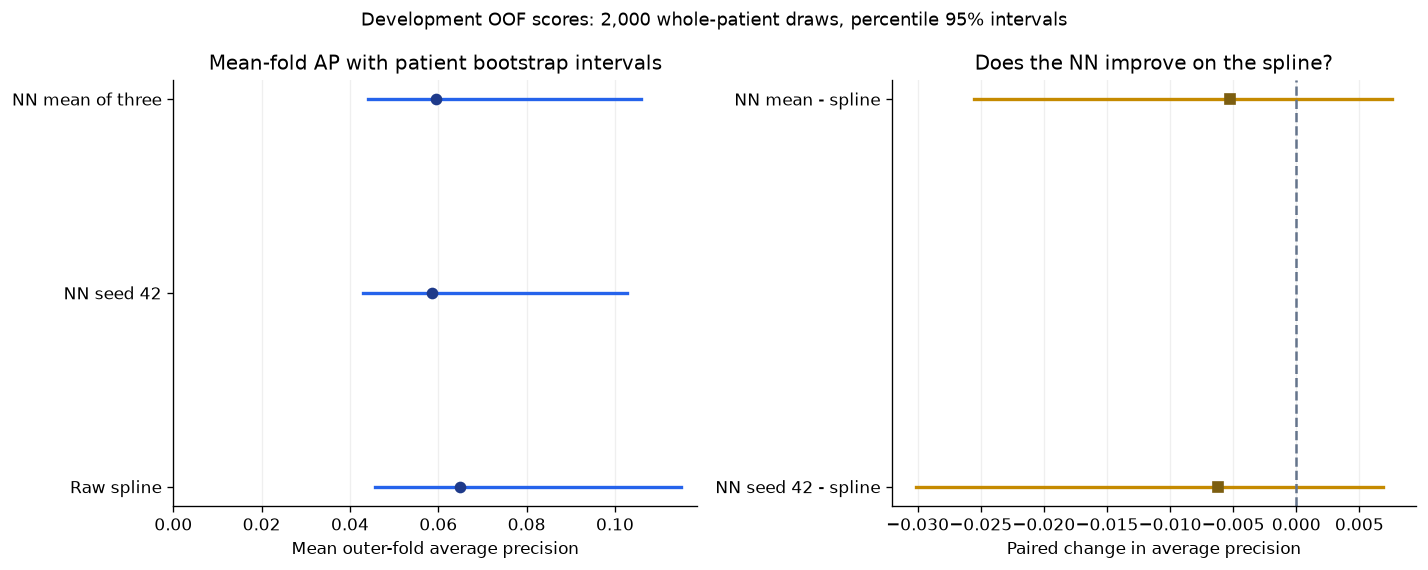

In [4]:

probability_sets = {"Raw spline": scores["spline_raw"], "Recalibrated spline": outer_predictions.p_spline_calibrated.to_numpy(),
    "NN seed 42": scores["nn_seed_42"], "NN seed 142": scores["nn_seed_142"], "NN seed 242": scores["nn_seed_242"],
    "NN mean of three": scores["metadata_nn_mean"]}
intervals_all = metadata_patient_intervals(frame, probability_sets, BOOTSTRAP_REPETITIONS)
save_metadata_table(ROOT, NOTEBOOK_STAGE, "paired_patient_intervals_all_aggregations", intervals_all)
intervals = intervals_all.query("aggregation == 'mean_fold'").copy()
display(intervals.loc[intervals.metric.isin(["average_precision", "roc_auc"]),
                      ["model_name", "reference_model", "metric", "estimate", "ci_lower", "ci_upper", "n_valid"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
selected = ["Raw spline", "NN seed 42", "NN mean of three"]
for index, name in enumerate(selected):
    row = intervals[(intervals.model_name == name) & intervals.reference_model.isna() & (intervals.metric == "average_precision")].iloc[0]
    axes[0].plot([row.ci_lower, row.ci_upper], [index, index], color="#2563EB", linewidth=2)
    axes[0].plot(row.estimate, index, "o", color="#1E3A8A")
axes[0].set_yticks(range(len(selected)), selected)
axes[0].set_xlim(left=0)
axes[0].set_xlabel("Mean outer-fold average precision")
axes[0].set_title("Mean-fold AP with patient bootstrap intervals")
for index, name in enumerate(["NN seed 42", "NN mean of three"]):
    row = intervals[(intervals.model_name == name) & (intervals.reference_model == "Raw spline") & (intervals.metric == "average_precision")].iloc[0]
    axes[1].plot([row.ci_lower, row.ci_upper], [index, index], color="#C58A00", linewidth=2)
    axes[1].plot(row.estimate, index, "s", color="#7C5E10")
axes[1].axvline(0, color="#64748B", linestyle="--")
axes[1].set_yticks([0, 1], ["NN seed 42 - spline", "NN mean - spline"])
axes[1].set_xlabel("Paired change in average precision")
axes[1].set_title("Does the NN improve on the spline?")
for axis in axes: axis.grid(axis="x", alpha=0.2)
fig.suptitle("Development OOF scores: 2,000 whole-patient draws, percentile 95% intervals", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "metadata_patient_bootstrap_d1.png", dpi=180, bbox_inches="tight")
finish_figure(fig, 'metadata_paired_patient_intervals')

### 5. Read calibration and score distributions

Group scores into five roughly equal-sized bins without splitting identical scores. Blue circles are the raw spline; gold squares are its training-only recalibrated version. Axis fractions such as 0.03 mean 3%.

- **Left: calibration.** Horizontal position is mean estimated probability; vertical position is observed malignant share. The dashed diagonal means agreement. Above it indicates underestimated risk; below it indicates overestimated risk. Vertical lines are 95% patient-bootstrap intervals for the observed rate, holding bins fixed. They do not describe uncertainty in horizontal position.
- **Right: score distribution.** Horizontal position is predicted probability; outline height counts images. Blue and gold show how recalibration moves the scores, most of which remain small.

Read the bin counts and error measures too. Few malignant cases make the curve noisy; Brier score and log loss reflect ranking as well as calibration. Recalibration is not automatically an improvement.


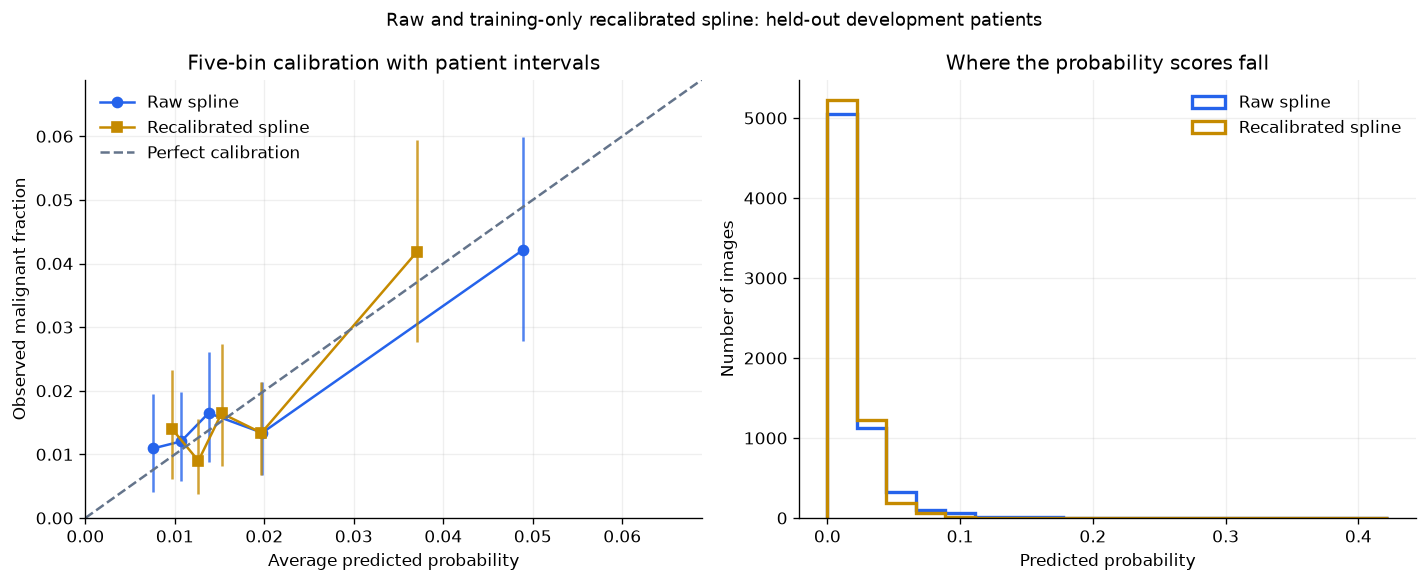

,model,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,observed_lower,observed_upper
0,Raw spline,1,1371,15,0.0076,0.0109,0.0028,0.0092,121,0.0042,0.0195
1,Raw spline,2,1329,16,0.0107,0.0120,0.0092,0.0119,162,0.0057,0.0198
2,Raw spline,3,1334,22,0.0138,0.0165,0.0119,0.0160,187,0.0088,0.0261
3,Raw spline,4,1344,18,0.0198,0.0134,0.0162,0.0251,203,0.0068,0.0214
4,Raw spline,5,1328,56,0.0489,0.0422,0.0254,0.4213,198,0.0279,0.0599
5,Recalibrated spline,1,1353,19,0.0097,0.0140,0.0044,0.0112,127,0.0061,0.0233
6,Recalibrated spline,2,1334,12,0.0126,0.0090,0.0112,0.0140,168,0.0038,0.0156
7,Recalibrated spline,3,1337,22,0.0152,0.0165,0.0140,0.0169,173,0.0082,0.0274
8,Recalibrated spline,4,1345,18,0.0197,0.0134,0.0170,0.0234,204,0.0068,0.0214
9,Recalibrated spline,5,1337,56,0.0371,0.0419,0.0237,0.2513,199,0.0277,0.0594


,procedure,average_precision,roc_auc,log_loss,brier
0,Raw spline,0.04921,0.64283,0.09095,0.01841
1,Recalibrated spline,0.04781,0.63810,0.09078,0.01840


In [5]:

def bin_rate_intervals(analysis_frame, probabilities, bins, repetitions=2000):
    table = reliability_table(analysis_frame, {"current": probabilities}, repetitions=repetitions)
    return table[["bin", "observed_lower", "observed_upper"]]
calibration_tables =  []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.9))
for name, color, marker in [("Raw spline", "#2563EB", "o"), ("Recalibrated spline", "#C58A00", "s")]:
    probabilities = probability_sets[name]
    bins = calibration_bins(train.target, probabilities, n_bins=5, groups=train.patient_id)
    bins = bins.merge(bin_rate_intervals(train, probabilities, bins), on="bin", validate="one_to_one")
    bins.insert(0, "model", name)
    calibration_tables.append(bins)
    axes[0].plot(bins.mean_probability, bins.observed_rate, marker=marker, color=color, label=name)
    axes[0].vlines(bins.mean_probability, bins.observed_lower, bins.observed_upper, color=color, alpha=0.8)
    axes[1].hist(probabilities, bins=np.linspace(0, max(probability_sets["Raw spline"].max(), probability_sets["Recalibrated spline"].max()) + .001, 20), histtype="step", linewidth=2, color=color, label=name)
calibration_table = pd.concat(calibration_tables, ignore_index=True)
calibration_table.to_csv(TABLES / "metadata_calibration_bins_d1.csv", index=False)
limit = max(calibration_table.mean_probability.max(), calibration_table.observed_upper.max()) * 1.15
axes[0].plot([0, limit], [0, limit], linestyle="--", color="#64748B", label="Perfect calibration")
axes[0].set(xlim=(0, limit), ylim=(0, limit), xlabel="Average predicted probability", ylabel="Observed malignant fraction", title="Five-bin calibration with patient intervals")
axes[1].set(xlabel="Predicted probability", ylabel="Number of images", title="Where the probability scores fall")
for axis in axes:
    axis.legend(frameon=False); axis.grid(alpha=0.2)
fig.suptitle("Raw and training-only recalibrated spline: held-out development patients", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "metadata_calibration_d1.png", dpi=180, bbox_inches="tight")
finish_figure(fig, 'metadata_reliability_and_score_distributions')
display(calibration_table.round(4))
display(pd.DataFrame([{"procedure": name, **probability_metrics(train.target, probability_sets[name])}
                      for name in ["Raw spline", "Recalibrated spline"]]).round(5))

### 6. Assess the cutoff trade-off on outer patients

Each outer fold keeps the cutoff selected from its own training data. We combine those decisions without choosing a more favourable cutoff from the outer labels.

In the first table, TP and FN count malignant images found and missed; FP and TN count benign images flagged and left unflagged. Sensitivity is the fraction of malignant images found, specificity is the fraction of benign images left unflagged, and precision is the fraction of flagged images that are malignant. The flagged fraction shows the review workload.

The second table gives 95% patient-bootstrap intervals for those proportions. These keep the saved decisions fixed rather than reselecting a cutoff in each draw. The raw and recalibrated procedures make the same decisions in this run: they find 102 of 127 malignant images and flag 4,597 of 6,706 images.


In [6]:
decision_rows, decision_ci_tables =  [], []
for name, column in [("Raw spline", "decision_raw"), ("Recalibrated spline", "decision_calibrated")]:
    decision_rows.append({"procedure": name, **decision_metrics(train.target, outer_predictions[column])})
    ci = decision_intervals(train, outer_predictions[column]); ci.insert(0, "procedure", name)
    decision_ci_tables.append(ci)
decision_summary = pd.DataFrame(decision_rows)
decision_ci = pd.concat(decision_ci_tables, ignore_index=True)
decision_summary.to_csv(METRICS / "metadata_nested_threshold_metrics_d1.csv", index=False)
decision_ci.to_csv(METRICS / "metadata_nested_threshold_intervals_d1.csv", index=False)
display(decision_summary.round(4))
display(decision_ci.round(4))

,procedure,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,Raw spline,102,4495,2084,25,0.8031,0.3168,0.0222,0.6855
1,Recalibrated spline,102,4495,2084,25,0.8031,0.3168,0.0222,0.6855


,procedure,metric,estimate,ci_lower,ci_upper,valid_draws,requested_draws
0,Raw spline,sensitivity,0.8031,0.7163,0.8889,2000,2000
1,Raw spline,specificity,0.3168,0.2648,0.3696,2000,2000
2,Raw spline,precision,0.0222,0.0167,0.0285,2000,2000
3,Raw spline,flagged_fraction,0.6855,0.6327,0.7372,2000,2000
4,Recalibrated spline,sensitivity,0.8031,0.7163,0.8889,2000,2000
5,Recalibrated spline,specificity,0.3168,0.2648,0.3696,2000,2000
6,Recalibrated spline,precision,0.0222,0.0167,0.0285,2000,2000
7,Recalibrated spline,flagged_fraction,0.6855,0.6327,0.7372,2000,2000


### 7. Read the age, sex and site checks

Each group uses raw spline scores and one common training-selected cutoff procedure. No group-specific cutoff is tuned. Age bands below 50 and 50 or older are fixed reporting groups.

The three panels show age, sex and site. Rows name groups; horizontal position is AP, with larger values meaning better ranking. Blue circles are observed AP and lines are 95% intervals from 1,000 whole-patient draws within the group and its original outer-fold strata. Labels count patients with a malignant image. Crosses mark fewer than ten such patients, with intervals suppressed; `AP undefined` means no malignant images to assess ranking.

Check counts, malignant share and sensitivity in the table before comparing groups. AP depends partly on how common malignancy is, so it cannot establish fairness alone. Sparse groups and wide intervals limit conclusions, and one patient can appear in multiple age or site groups.


,field,group,images,patients,positive_images,positive_patients,prevalence,average_precision,average_precision_lower,average_precision_upper,sensitivity,evidence_note
0,Age band,<50,2981,189,32,23,0.0107,0.0126,0.0074,0.0263,0.4375,Exploratory; shared frozen cutoff; no subgroup...
1,Age band,>=50,3725,269,95,65,0.0255,0.0660,0.0423,0.1177,0.9263,Exploratory; shared frozen cutoff; no subgroup...
2,Sex,female,3477,204,53,37,0.0152,0.0338,0.0203,0.0816,0.7170,Exploratory; shared frozen cutoff; no subgroup...
3,Sex,male,3229,218,74,51,0.0229,0.0626,0.0368,0.1206,0.8649,Exploratory; shared frozen cutoff; no subgroup...
4,Site,Unknown,195,53,2,2,0.0103,0.0777,NaN,NaN,1.0000,Sparse: fewer than 10 malignant patients; inte...
5,Site,head/neck,393,179,21,21,0.0534,0.1433,0.0728,0.2976,1.0000,Exploratory; shared frozen cutoff; no subgroup...
6,Site,lower extremity,1620,327,25,23,0.0154,0.0459,0.0143,0.0965,0.7200,Exploratory; shared frozen cutoff; no subgroup...
7,Site,oral/genital,33,20,3,2,0.0909,0.0842,NaN,NaN,1.0000,Sparse: fewer than 10 malignant patients; inte...
8,Site,palms/soles,70,40,0,0,0.0000,NaN,NaN,NaN,NaN,Sparse: fewer than 10 malignant patients; inte...
9,Site,torso,3351,398,54,41,0.0161,0.0385,0.0221,0.0682,0.7037,Exploratory; shared frozen cutoff; no subgroup...


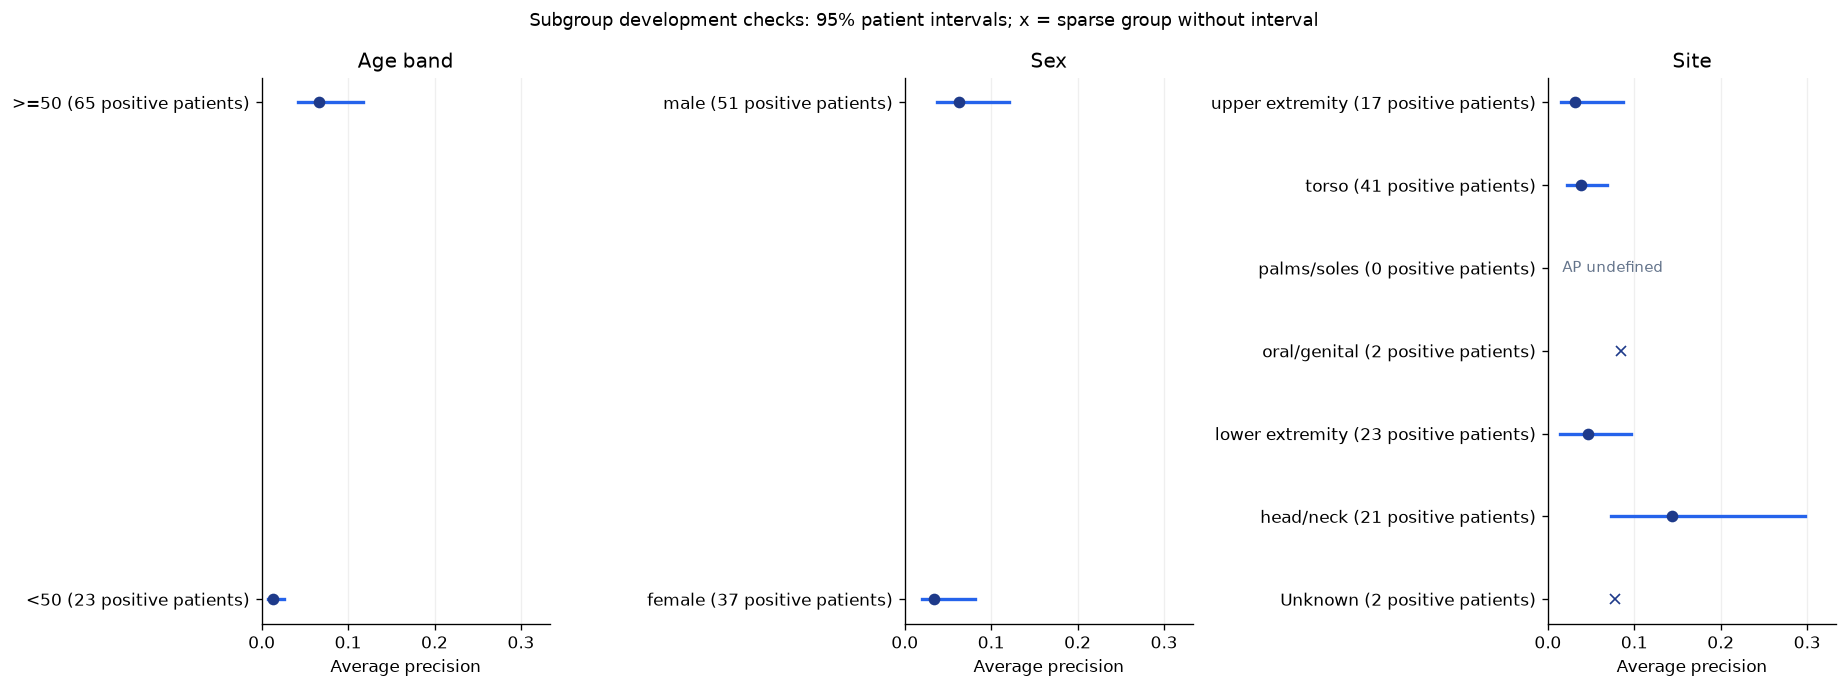

In [7]:

subgroup_table = subgroup_diagnostics(train, outer_predictions.p_spline_raw.to_numpy(),
    outer_predictions.decision_raw.to_numpy(), repetitions=1000)
subgroup_table = subgroup_table.loc[subgroup_table.field.ne("Site availability")].copy()
subgroup_table = subgroup_table.rename(columns={"malignant_images": "positive_images", "malignant_patients": "positive_patients"})
subgroup_table["sensitivity_lower"], subgroup_table["sensitivity_upper"] = np.nan, np.nan
ages = pd.to_numeric(train.age_approx, errors="coerce")
report_groups = {"Age band": pd.Series(np.where(ages.isna(), "Missing", np.where(ages < 50, "<50", ">=50")), index=train.index),
    "Sex": train.sex.fillna("Missing").astype(str), "Site": train.anatom_site_general_challenge.fillna("Missing").astype(str)}
for index, row in subgroup_table.iterrows():
    if row.positive_patients >= 10:
        mask = report_groups[row.field].eq(row.group).to_numpy()
        subset = train.loc[mask].reset_index(drop=True)
        ci = decision_intervals(subset, outer_predictions.loc[mask, "decision_raw"].to_numpy(), repetitions=1000)
        interval = ci.query("metric == 'sensitivity'").iloc[0]
        subgroup_table.loc[index, ["sensitivity_lower", "sensitivity_upper"]] = [interval.ci_lower, interval.ci_upper]
save_metadata_table(ROOT, NOTEBOOK_STAGE, "subgroup_checks", subgroup_table)
display(subgroup_table[["field", "group", "images", "patients", "positive_images", "positive_patients", "prevalence",
    "average_precision", "average_precision_lower", "average_precision_upper", "sensitivity", "evidence_note"]].round(4))
fig, axes =  plt.subplots(1, 3, figsize=(15.5, 5.8), sharex=True)
subgroup_maximum = max(subgroup_table.average_precision.max(), subgroup_table.average_precision_upper.max()) * 1.12
for axis, field in zip(axes, report_groups):
    rows = subgroup_table[subgroup_table.field.eq(field)].reset_index(drop=True)
    for index, row in rows.iterrows():
        if pd.notna(row.average_precision_lower):
            axis.plot([row.average_precision_lower, row.average_precision_upper], [index, index], color="#2563EB", linewidth=2)
        axis.plot(row.average_precision, index, "o" if row.positive_patients >= 10 else "x", color="#1E3A8A")
        if pd.isna(row.average_precision):
            axis.text(subgroup_maximum * .05, index, "AP undefined", va="center", fontsize=9, color="#64748B")
    axis.set_yticks(range(len(rows)), [f"{row.group} ({row.positive_patients} positive patients)" for row in rows.itertuples()])
    axis.set_title(field); axis.set_xlabel("Average precision"); axis.set_xlim(0, subgroup_maximum); axis.grid(axis="x", alpha=0.2)
fig.suptitle("Subgroup development checks: 95% patient intervals; x = sparse group without interval", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "metadata_subgroups_d1.png", dpi=180, bbox_inches="tight")
finish_figure(fig, 'metadata_subgroup_support_and_intervals')

### 8. Prepare the retained model for later final fitting and testing

Keep the previously chosen raw four-knot spline as the development comparator. The original stage fitted it on all development patients and selected its academic cutoff from five-fold development OOF scores, then saved the model, cutoff, training identities, source fingerprints and dependency versions. That combination gives a later test script a complete fixed recipe.

**Experiment-scope change:** this clean report deliberately defers all-development fitting until the final procedure is chosen. It reads the five clean outer models and their training-selected calibration/cutoff artifacts; these support development evaluation, rather than providing a final deployable model. The historical `models/metadata_d1` bundle belongs to the original 6,864-image data and cannot be relabelled as deduplicated.

After settling features, model settings, calibration and cutoff rules, fit a separately named clean bundle on all 6,706 development records, preserving patient identities and exact deduplication fingerprints. Verify reserved-test patient/image separation and the consistent duplicate policy before scoring. Evaluate once with the saved procedure, without adjusting it to improve the test result. This notebook performs neither that fit nor the test.

In [8]:

display(pd.DataFrame([{"chosen_development_comparator": "Raw four-knot spline; C=1",
    "fitted_clean_final_model": False, "reserved_test_loaded": False,
    "historical_final_bundle": "models/metadata_d1/frozen_spline.joblib",
    "next_required_step": "Settle the complete recipe, fit a separate clean all-development bundle, then test once"}]))
print("No final fit or final-test evaluation is performed by this report.")


,chosen_development_comparator,fitted_clean_final_model,reserved_test_loaded,historical_final_bundle,next_required_step
0,Raw four-knot spline; C=1,False,False,models/metadata_d1/frozen_spline.joblib,"Settle the complete recipe, fit a separate cle..."


No final fit or final-test evaluation is performed by this report.


### 9. Check the results together

The printed recap below brings together the AP comparison, its uncertainty interval, the cutoff's detection and review workload, and the number of sparse reporting groups. The recap uses primary mean-fold AP and its matching paired interval, alongside pooled image-level decision rates. Read these as development findings for the retained spline.


In [9]:

recap = metric_table(frame, {"spline_raw": probability_sets["Raw spline"], "metadata_nn_mean": probability_sets["NN mean of three"]},
    ["spline_raw", "metadata_nn_mean"]).query("scope == 'mean_fold'").set_index("model")
raw_ap, nn_ap = recap.loc["spline_raw", "average_precision"], recap.loc["metadata_nn_mean", "average_precision"]
delta = intervals[(intervals.model_name == "NN mean of three") & (intervals.reference_model == "Raw spline") & intervals.metric.eq("average_precision")].iloc[0]
raw_decisions = decision_summary.query("procedure == 'Raw spline'").iloc[0]
print(f"Primary mean-fold AP: raw spline {raw_ap:.4f}; mean-of-three NN {nn_ap:.4f}.")
print(f"NN minus spline mean-fold AP: {delta.estimate:+.4f}, patient 95% interval [{delta.ci_lower:+.4f}, {delta.ci_upper:+.4f}].")
print(f"Training-target recall: {TARGET_RECALL:.0%}; held-out raw-spline sensitivity: {raw_decisions.sensitivity:.1%}.")
print(f"At that policy, {raw_decisions.flagged_fraction:.1%} of images are flagged; precision is {raw_decisions.precision:.1%}.")
print(f"Sparse reporting groups: {int(subgroup_table.positive_patients.lt(10).sum())} of {len(subgroup_table)}.")
print("Primary development comparator remains the raw spline. Final clean fit is deferred; reserved test remains closed.")


Primary mean-fold AP: raw spline 0.0648; mean-of-three NN 0.0596.
NN minus spline mean-fold AP: -0.0053, patient 95% interval [-0.0255, +0.0076].
Training-target recall: 80%; held-out raw-spline sensitivity: 80.3%.
At that policy, 68.6% of images are flagged; precision is 2.2%.
Sparse reporting groups: 3 of 11.
Primary development comparator remains the raw spline. Final clean fit is deferred; reserved test remains closed.


## Limitations

These folds have already guided model comparisons. Keeping calibration and cutoff selection within training prevents direct outer-label reuse for those steps, but cannot undo earlier model exploration. Independent final testing is still needed after decisions are fixed.

Bootstrap intervals hold predictions and decisions fixed. They cover patient-sampling variation, without including retraining, method selection or a new hospital. Multiple exploratory comparisons are not adjusted for repeated testing.

Only 127 images are malignant; three of eleven reporting groups have fewer than ten patients with a malignant image. AP changes with malignant prevalence, and sparse subgroup results cannot establish fairness or causation. Five calibration bins can hide within-bin differences.

The 80% recall target is an academic scenario. Flagging roughly 69% of images does not establish acceptable clinical workload or safety. The metadata model predicts image outcomes without seeing lesion appearance.


## Summary

The raw spline has primary mean-fold AP 0.0648; the three-network mean has 0.0596. Their difference is -0.0053 with a 95% paired patient interval of [-0.0255, +0.0076], giving no clear network improvement. The original-style pooled AP values are 0.0492 and 0.0477. Recalibration slightly lowers probability error; within-fold ranking is unchanged by its monotonic mapping, although pooled ranking shifts because folds use different mappings.

Keep the raw spline as the predeclared development comparator. The training-selected 80% recall scenario finds 102 of 127 malignant images (80.3%), flags 4,597 of 6,706 images (68.6%) and has 2.2% precision. Raw and recalibrated procedures make the same decisions here. That workload limits metadata alone, and three of eleven age/sex/site reporting groups have fewer than ten malignant patients.

**Final clean fitting remains deferred.** Existing outer models and cutoffs are saved for development assessment; the historical original-data final bundle remains preserved. The reserved test has not been evaluated. Next, [09_image_modelling.ipynb](09_image_modelling.ipynb) assesses clean image information. Complete and freeze the modelling procedure before fitting a separate clean final bundle and evaluating the reserved test once.

## Additional deduplicated-workflow diagnostics

The complete original section sequence above is retained as the template. The following clearly labelled additions document clean artifact verification, training support and explanatory diagnostics that were not figures in the original. They remain secondary development evidence and do not select another model or cutoff.

In [10]:

import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))


,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


In [11]:
calibration = meta["calibration"]

In [12]:
COLORS = ['#2563EB', '#C58A00', '#6B7F2A', '#EA580C', '#303030', '#94A3B8']

### Added diagnostic: 3. Compare probability error and equal-patient weighting

Raw versus recalibrated score error must be assessed on outer patients. Equal-patient image weights 1/(retained images for that patient) provide a secondary diagnostic for unequal patient contribution; they do not convert the task into patient cancer diagnosis or change the primary metric.

In [13]:
probabilities = {"spline_raw": calibration.p_spline_raw.to_numpy(), "spline_calibrated": calibration.p_spline_calibrated.to_numpy(), "metadata_nn_mean": scores["metadata_nn_mean"]}
display(metric_table(frame, probabilities, list(probabilities)).query("scope != 'fold'").round(5))
from sklearn.metrics import average_precision_score, roc_auc_score
weights = 1 / frame.groupby("patient_id").patient_id.transform("size").to_numpy()
display(pd.DataFrame([{"model": LABELS[name], "pooled_image_AP": average_precision_score(frame.target, values), "equal_patient_AP": average_precision_score(frame.target, values, sample_weight=weights), "pooled_image_AUC": roc_auc_score(frame.target, values), "equal_patient_AUC": roc_auc_score(frame.target, values, sample_weight=weights)} for name, values in probabilities.items()]).round(5))

,model,scope,fold,average_precision,roc_auc,log_loss,brier
5,spline_raw,mean_fold,NaN,0.06484,0.65563,0.09101,0.01842
6,spline_raw,pooled,NaN,0.04921,0.64283,0.09095,0.01841
12,spline_calibrated,mean_fold,NaN,0.06484,0.65563,0.09083,0.01841
13,spline_calibrated,pooled,NaN,0.04781,0.63810,0.09078,0.01840
19,metadata_nn_mean,mean_fold,NaN,0.05957,0.67669,0.09017,0.01838
20,metadata_nn_mean,pooled,NaN,0.04768,0.66946,0.09011,0.01837


,model,pooled_image_AP,equal_patient_AP,pooled_image_AUC,equal_patient_AUC
0,Fixed spline,0.04921,0.10143,0.64283,0.69201
1,Training-only recalibrated spline,0.04781,0.10203,0.63810,0.68965
2,Three-seed NN mean,0.04768,0.08996,0.66946,0.71335


### Added diagnostic: 5. Assess frozen cutoffs on outer patients

Each outer fold uses its own training-selected cutoff. Combine its saved decisions without choosing another cutoff from outer labels. Sensitivity counts malignant images found; specificity counts benign images left unflagged; precision is malignant share among flags; flagged fraction estimates review workload. These are image-level decisions with patient-cluster uncertainty.

,procedure,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,Fixed spline,102,4495,2084,25,0.80315,0.31677,0.02219,0.68551
1,Training-only recalibrated spline,102,4495,2084,25,0.80315,0.31677,0.02219,0.68551


,procedure,metric,estimate,ci_lower,ci_upper,valid_draws,requested_draws
0,Fixed spline,sensitivity,0.80315,0.71629,0.88889,2000,2000
1,Fixed spline,specificity,0.31677,0.26478,0.36956,2000,2000
2,Fixed spline,precision,0.02219,0.01675,0.02852,2000,2000
3,Fixed spline,flagged_fraction,0.68551,0.63269,0.73724,2000,2000
4,Training-only recalibrated spline,sensitivity,0.80315,0.71629,0.88889,2000,2000
5,Training-only recalibrated spline,specificity,0.31677,0.26478,0.36956,2000,2000
6,Training-only recalibrated spline,precision,0.02219,0.01675,0.02852,2000,2000
7,Training-only recalibrated spline,flagged_fraction,0.68551,0.63269,0.73724,2000,2000


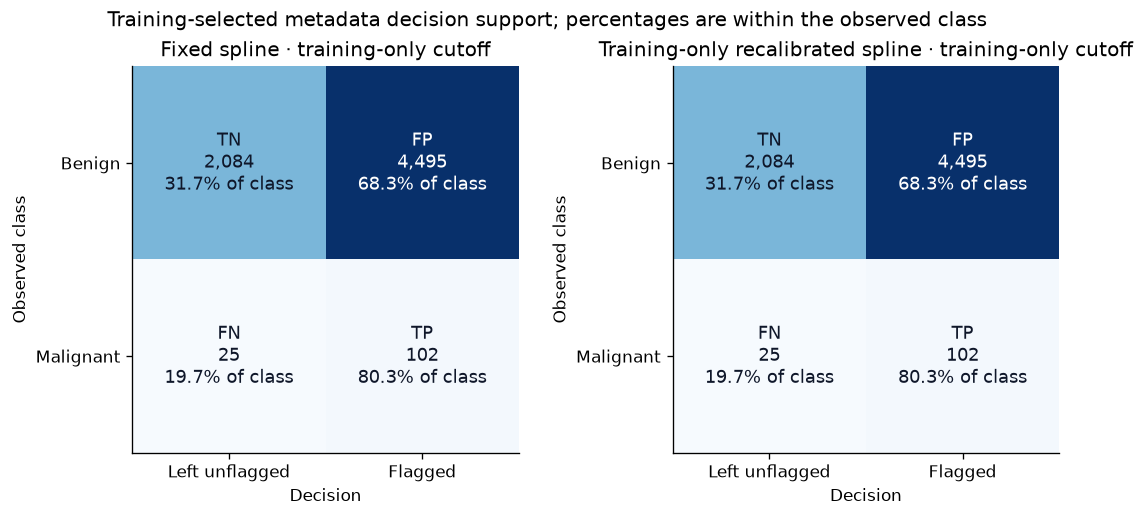

In [14]:
decision_rows, interval_rows = [], []
for scale, name in [("raw", "spline_raw"), ("calibrated", "spline_calibrated")]:
    decisions = calibration[f"decision_{scale}"].to_numpy()
    decision_rows.append({"procedure": LABELS[name], **decision_metrics(frame.target, decisions)})
    ci = decision_intervals(frame, decisions)
    ci.insert(0, "procedure", LABELS[name]); interval_rows.append(ci)
decision_summary = pd.DataFrame(decision_rows)
decision_ci = pd.concat(interval_rows, ignore_index=True)
display(decision_summary.round(5)); display(decision_ci.round(5))
save_metadata_table(ROOT, "12_combined_evaluation", "training_only_decision_summary", decision_summary)
save_metadata_table(ROOT, "12_combined_evaluation", "training_only_decision_intervals", decision_ci)
scenarios = [(LABELS[name] + " · training-only cutoff", calibration[column].to_numpy()) for name, column in [("spline_raw", "decision_raw"), ("spline_calibrated", "decision_calibrated")]]
finish_figure(confusion_figure(frame.target, scenarios, "Training-selected metadata decision support"), "metadata_training_only_confusions")

### Added diagnostic: 6. Read detection and review-workload intervals

The same 2,000 patient draws assess raw and recalibrated frozen decisions. Intervals do not reselect cutoffs in each draw or guarantee a clinical workload. Undefined rates retain missing values, and valid-draw counts show whether scarce classes limit estimation.

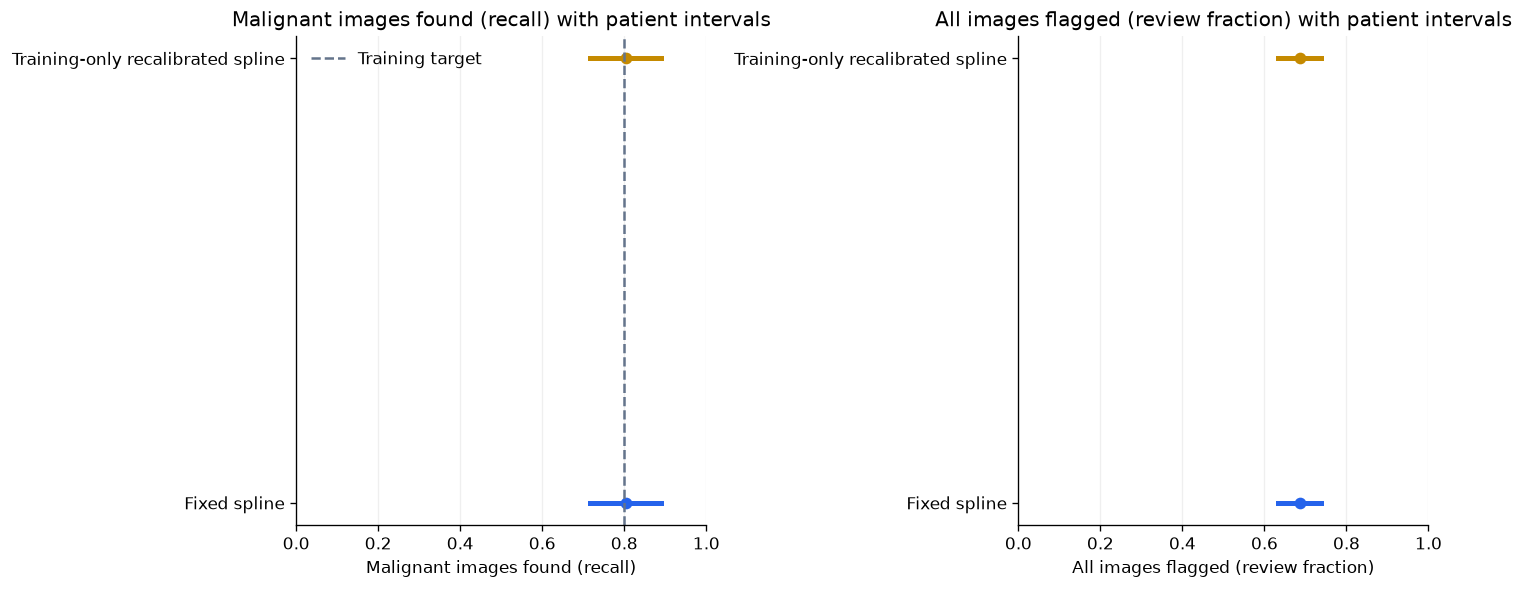

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, metric, label in zip(axes, ["sensitivity", "flagged_fraction"], ["Malignant images found (recall)", "All images flagged (review fraction)"]):
    rows = decision_ci.loc[decision_ci.metric.eq(metric)].reset_index(drop=True)
    for index, row in rows.iterrows():
        ax.plot([row.ci_lower, row.ci_upper], [index, index], color=COLORS[index], linewidth=3)
        ax.plot(row.estimate, index, "o", color=COLORS[index])
    ax.set(yticks=range(len(rows)), yticklabels=rows.procedure, xlabel=label, title=label + " with patient intervals", xlim=(0, 1))
    ax.grid(axis="x", alpha=.2)
axes[0].axvline(.8, color="#64748b", linestyle="--", label="Training target")
axes[0].legend(frameon=False)
finish_figure(fig, "metadata_detection_and_review_intervals")

### Added diagnostic: 7. Check age, sex, site and site availability with support

Use raw spline scores and the same frozen decision procedure for every subgroup; no subgroup-specific cutoff is fitted. AP depends partly on malignant prevalence. One patient's images may occupy multiple age/site groups, so counts cannot be summed as independent patients. Secondary intervals use 2,000 seed-42 whole-patient draws within outer folds. Fewer than ten malignant patients triggers interval suppression as a reporting caution, not a zero metric; undefined values remain missing.

,field,group,images,patients,malignant_images,malignant_patients,prevalence,average_precision,roc_auc,sensitivity,precision,flagged_fraction,valid_draws,evidence_note
0,Age band,<50,2981,189,32,23,0.01073,0.01262,0.48331,0.43750,0.01256,0.37404,2000,Exploratory; shared frozen cutoff; no subgroup...
1,Age band,>=50,3725,269,95,65,0.02550,0.06599,0.63982,0.92632,0.02527,0.93477,2000,Exploratory; shared frozen cutoff; no subgroup...
2,Sex,female,3477,204,53,37,0.01524,0.03378,0.62111,0.71698,0.01913,0.57118,2000,Exploratory; shared frozen cutoff; no subgroup...
3,Sex,male,3229,218,74,51,0.02292,0.06256,0.64997,0.86486,0.02451,0.80861,2000,Exploratory; shared frozen cutoff; no subgroup...
4,Site,Unknown,195,53,2,2,0.01026,0.07772,0.58290,1.00000,0.01235,0.83077,0,Sparse: fewer than 10 malignant patients; inte...
5,Site,head/neck,393,179,21,21,0.05344,0.14327,0.67531,1.00000,0.05344,1.00000,2000,Exploratory; shared frozen cutoff; no subgroup...
6,Site,lower extremity,1620,327,25,23,0.01543,0.04594,0.59136,0.72000,0.01739,0.63889,2000,Exploratory; shared frozen cutoff; no subgroup...
7,Site,oral/genital,33,20,3,2,0.09091,0.08425,0.17222,1.00000,0.09091,1.00000,0,Sparse: fewer than 10 malignant patients; inte...
8,Site,palms/soles,70,40,0,0,0.00000,NaN,NaN,NaN,0.00000,0.58571,0,Sparse: fewer than 10 malignant patients; inte...
9,Site,torso,3351,398,54,41,0.01611,0.03852,0.62922,0.70370,0.01890,0.60012,2000,Exploratory; shared frozen cutoff; no subgroup...


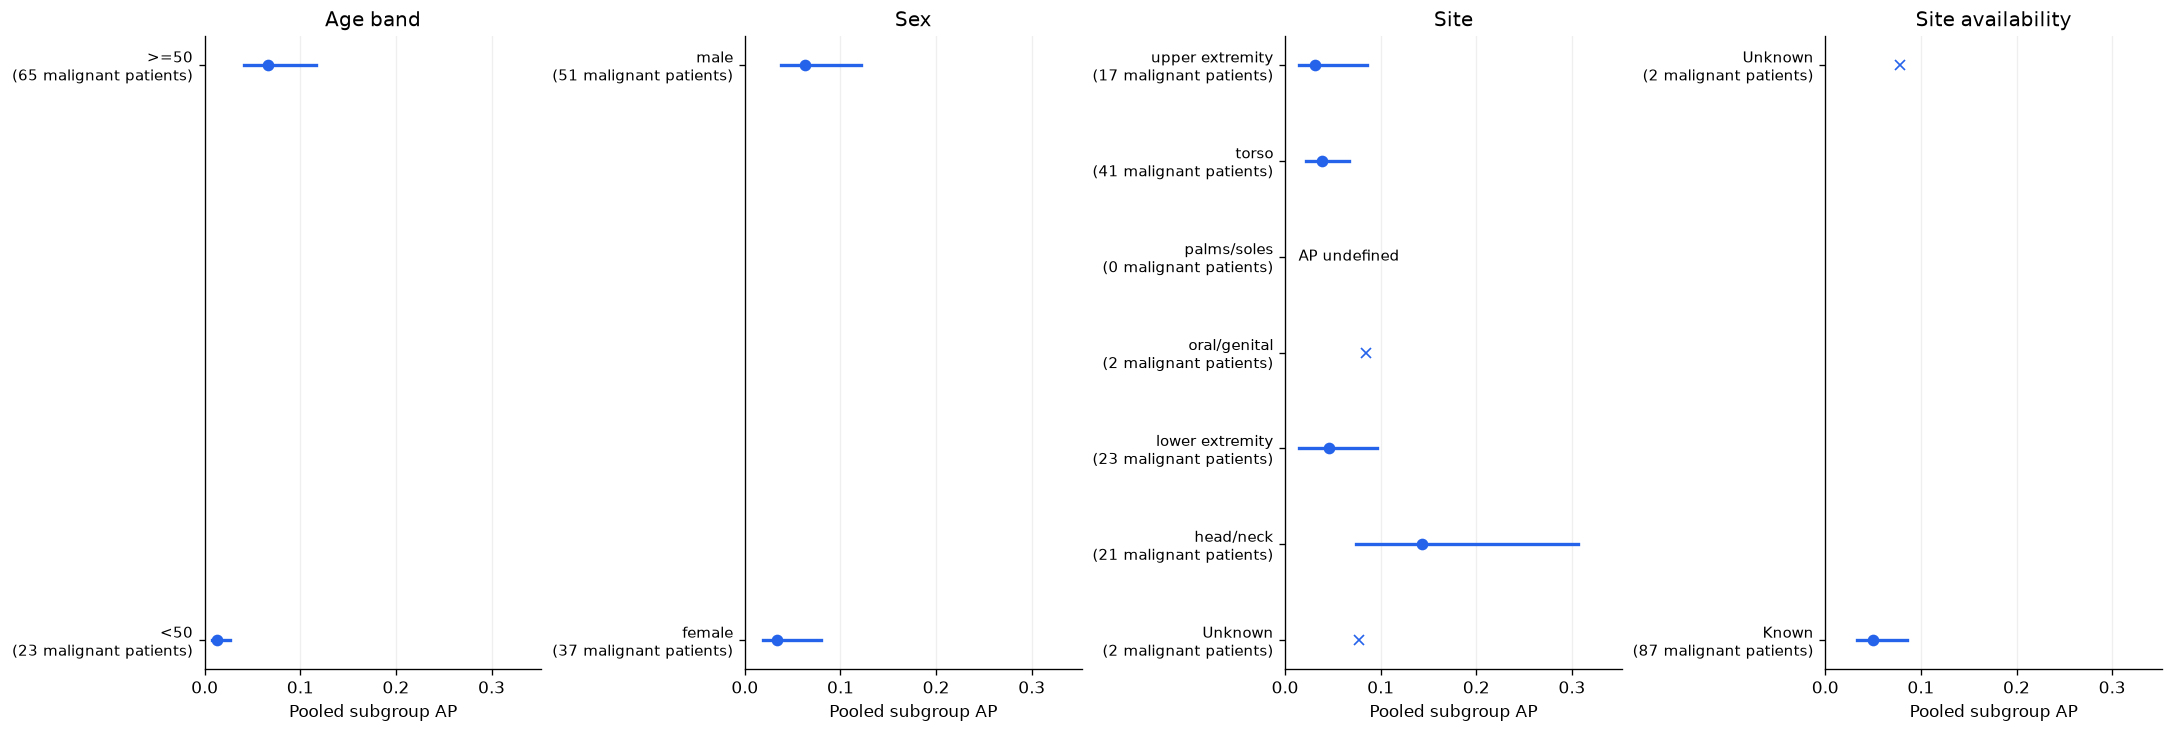

In [16]:
diagnostic_frame = bundle["frame"].set_index("image_name").loc[frame.image_id].reset_index()
subgroups = subgroup_diagnostics(diagnostic_frame, calibration.p_spline_raw.to_numpy(), calibration.decision_raw.to_numpy())
save_metadata_table(ROOT, "12_combined_evaluation", "subgroup_diagnostics_with_patient_support", subgroups)
display(subgroups[["field", "group", "images", "patients", "malignant_images", "malignant_patients", "prevalence", "average_precision", "roc_auc", "sensitivity", "precision", "flagged_fraction", "valid_draws", "evidence_note"]].round(5))
fig, axes = plt.subplots(1, 4, figsize=(18, 6), layout="constrained")
limit = max(float(subgroups.average_precision.max()), float(subgroups.average_precision_upper.max())) * 1.15
for ax, field in zip(axes, ["Age band", "Sex", "Site", "Site availability"]):
    rows = subgroups.loc[subgroups.field.eq(field)].reset_index(drop=True)
    for index, row in rows.iterrows():
        if pd.notna(row.average_precision_lower): ax.plot([row.average_precision_lower, row.average_precision_upper], [index, index], color="#2563eb", linewidth=2)
        if pd.notna(row.average_precision): ax.plot(row.average_precision, index, "o" if row.malignant_patients >= 10 else "x", color="#2563eb")
        else: ax.text(limit * .04, index, "AP undefined", va="center", fontsize=9)
    ax.set(yticks=range(len(rows)), yticklabels=[f"{row.group}\n({row.malignant_patients} malignant patients)" for row in rows.itertuples()], xlabel="Pooled subgroup AP", title=field, xlim=(0, limit))
    ax.tick_params(axis="y", labelsize=9); ax.grid(axis="x", alpha=.2)
finish_figure(fig, "metadata_subgroup_support_and_intervals")

## Continue with the matching clean image evaluation

The original metadata-robustness sections above establish probability, decision and subgroup interpretation. The original five-fold image report follows with the same retained image and patient identities. Only then does the combined comparison add paired model differences, equal-patient weighting and explicit completion checks. Saved clean fits are read throughout; no final all-development fit or reserved-test evaluation is performed here.

# Clean image model: five preserved outer folds

## tl;dr

This report evaluates the bounded B0 recipe and duration selection process on five patient
groups. Each outer fold supplies predictions from a model that did not use its
patients for fitting, recipe selection or epoch selection in this run.
The primary measure is **mean outer-fold average precision (AP)**. AP measures
how effectively melanoma images appear near the top of the model's ranking.
Higher is better; fold prevalence supplies a simple ranking baseline.

The notebook reads saved results only. It does not start training, fit
calibration, choose a cutoff or open the reserved test. A partial run displays
its progress and withholds final five-fold conclusions.


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [14_image_nested_evaluation.ipynb](../Subset/14_image_nested_evaluation.ipynb).

**Scope change:** exact copies are removed before fitting and evaluation.
The five-fold design matches the original nested-evaluation report; original pilot
outputs are never substituted for missing clean results.

In [17]:
from melanoma_detection import dedup_notebook_images as image_docs
from melanoma_detection.image_nested_calibration_reporting import load_saved_calibration_run
image_docs.original_style('image')
raw = load_image_report(ROOT)
calibration = load_saved_calibration_run(ROOT, image_docs.CALIBRATION_RUN)
display(pd.DataFrame([{'stage': 'raw five-fold B0', 'status': raw['status'], 'complete': raw['complete']},
    {'stage': 'training-only calibration', 'status': calibration['status'], 'complete': calibration['complete']}]))
ORIGINAL_EXPORT_DPI = 150


,stage,status,complete
0,raw five-fold B0,complete,True
1,training-only calibration,complete,True


## Context & Methods

The outer folds are the five existing patient groups in the frozen dedup_v1
development manifest; all 422 original patient assignments are preserved. The complete process repeats independently inside every outer
training pool:

1. Preserve the three recorded inner patient folds after removing exact copies. On the first inner fold, screen all **four
   B0 recipes for six epochs**: learning rate 3e-5 or 1e-4, crossed with unweighted
   or square-root-weighted loss. Only fitting patients determine the loss weight.
2. Choose the recipe with the highest screening AP. Scores within 0.0001 of the
   maximum tie; prefer unweighted loss and then the lower learning rate.
3. Confirm that selected recipe for **twelve total epochs on all three inner
   folds**. The compatible six-epoch first-fold checkpoint continues to twelve;
   the other two confirmation fits begin afresh.
4. Select the highest-AP epoch separately in each confirmation fit; exact ties
   keep the earlier epoch. The **median of those three best epochs** fixes the
   duration of a fresh refit on all outer training patients.
5. Predict the outer fold only after the fixed-duration refit completes. Outer
   labels do not guide fitting, recipe selection, epoch choice or stopping.

Confirmation AP chooses epochs inside training data; it is not outer performance.
The recipe and refit duration can differ between outer folds. Each retained
image must receive exactly one outer prediction; missing, duplicate, extra or
relabelled rows fail verification.

### Key Assumptions

Images from one patient remain together in every partition. AP and other
metrics concern individual images; the uncertainty calculation resamples
**patients**, keeping all their images together. Patients are sampled with
replacement separately within each fixed outer fold. Draws lacking either
outcome in any fold are discarded consistently across all reported measures.
The report records requested, retained and rejected draws.

These intervals condition on the saved models, recipe choices and folds. They
do not represent variability from retraining or repeating model selection.
Mean fold AP is primary because scores from separate fitted models can have
different scales; pooled AP is a secondary description.

Earlier architecture, augmentation and recipe pilots used the original development
population, and archived exploratory predictions used outer fold 0. Exact-copy removal
does not undo those earlier choices or make these patients newly untouched. This is
stronger **development evaluation**, but prior adaptation limits how fully it
represents an untouched evaluation. Freeze remaining decisions before the
single reserved-test evaluation.


In [18]:
image_docs.image_settings(ROOT)

,Setting,Value
0,architecture,efficientnet_b0
1,weights,IMAGENET1K_V1
2,image_size,224
3,dropout,0.2
4,augmentation,weak
5,preprocessing,none
6,microbatch,64
7,effective_batch,64
8,min_microbatch,4
9,head_lr,0.001


,id,backbone_lr,loss_weight
0,lr3e5_none,0.00003,none
1,lr1e4_none,0.00010,none
2,lr3e5_sqrt,0.00003,sqrt_ratio
3,lr1e4_sqrt,0.00010,sqrt_ratio


,Outer folds,Preserved inner folds,Screen epochs,Confirm epochs,Duration,Raw GPU fits,Calibration GPU fits,Fresh start
0,5,3,6,12,median of three saved AP-best epochs,35,15,IMAGENET1K_V1 for each distinct fit


### Recorded recipe and refit duration by outer fold

Each completed outer fold records the recipe chosen on its first inner split
and the fixed refit duration obtained from three confirmation fits. This table
documents what was selected, rather than ranking recipes using outer labels.
An unfinished fold keeps missing settings until its selection is saved.


In [19]:
image_docs.image_selection_table(ROOT, data)

,outer_fold,outer_images,outer_malignant_images,selected_recipe,inner_best_epochs,fixed_refit_epochs,status
0,0,1344,24,lr1e4_none,"[7, 11, 11]",11,complete
1,1,1366,26,lr1e4_none,"[9, 12, 7]",9,complete
2,2,1328,26,lr1e4_none,"[4, 3, 12]",4,complete
3,3,1371,25,lr1e4_none,"[8, 9, 10]",9,complete
4,4,1297,26,lr1e4_none,"[4, 9, 8]",8,complete


## Data

The verified population is the complete retained development cohort: 6,706 images, 422 patients,
127 malignant images and 88 patients with a malignant image. Counts
by fold make rare melanoma support and unequal image counts visible. All
models are scored on the same images when a metadata comparison is available.
No inner join can silently reduce the evaluation population.


In [20]:
if raw['complete']:
    display(raw['fold_metrics'][['fold', 'n_images', 'n_patients', 'n_positive', 'prevalence']])
else:
    display(Markdown('**Pending:** full retained population counts require five verified folds.'))

,fold,n_images,n_patients,n_positive,prevalence
0,0,1344,84,24,0.017857
1,1,1366,84,26,0.019034
2,2,1328,87,26,0.019578
3,3,1371,82,25,0.018235
4,4,1297,85,26,0.020046


## Results

### Ranking and fold variation

The fold table and AP plot show how ranking performance varies between patient
groups. The spread between five fold scores is descriptive variability, not a
confidence interval. Precision–recall is particularly informative here because
melanoma images are uncommon; ROC shows a complementary ranking view.


,fold,n_images,n_patients,n_positive,prevalence,average_precision,roc_auc,log_loss,brier
0,0,1344,84,24,0.0179,0.1525,0.8544,0.0955,0.0225
1,1,1366,84,26,0.0190,0.1489,0.8392,0.0902,0.0192
2,2,1328,87,26,0.0196,0.1487,0.8648,0.0823,0.0187
3,3,1371,82,25,0.0182,0.0573,0.7573,0.1382,0.0184
4,4,1297,85,26,0.0200,0.1504,0.8383,0.0893,0.0195


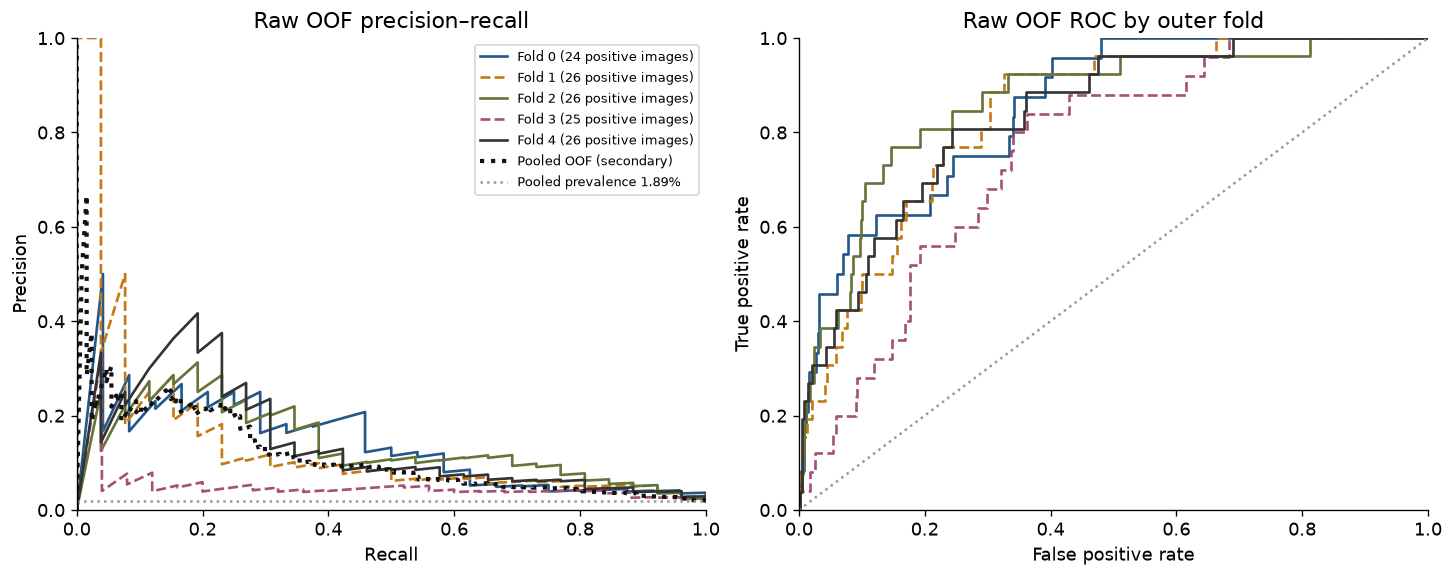

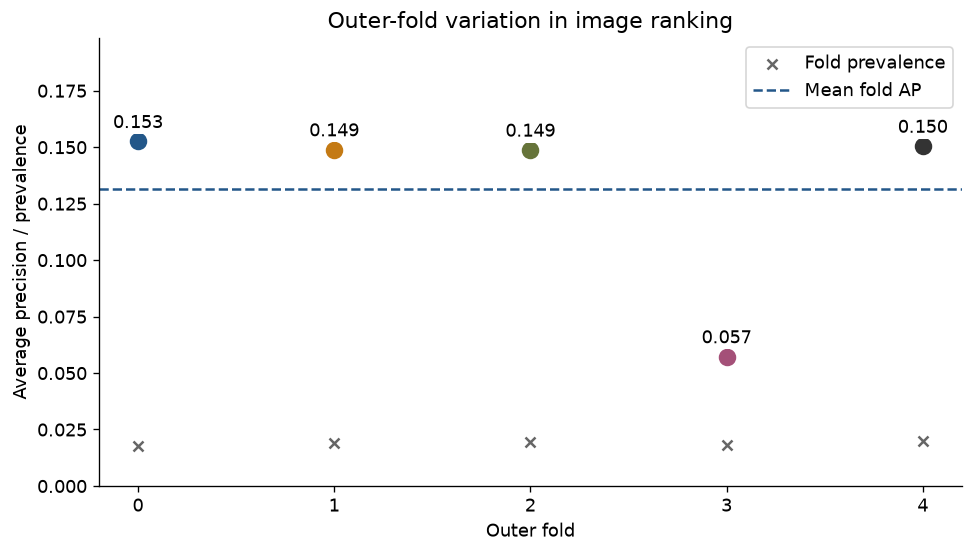

In [21]:
image_docs.raw_outer_ranking(raw, finish_figure)

### Raw probabilities and the declared 0.5 cutoff

Log loss and Brier score examine probability quality; lower is better. The
reliability plot compares mean raw score with the observed melanoma fraction
in fixed bins, and shows how many images support each point. It is descriptive:
sparse bins can be unstable. Class weighting can alter raw probability scale.

The confusion counts use the declared rule **raw score ≥ 0.5**. This cutoff is
a transparent default illustration, not a tuned operating point or a clinical
recommendation. No new threshold or calibration model is fitted by this report. The ten fixed-width
bins, image-count annotations and score histogram retain the original composition.
The added confusion panel reports both counts and percentages within true-class rows,
using the same blue scale as the original pilot notebooks.


,bin,lower,upper,n_images,n_positive,mean_probability,observed_prevalence
0,0,0.0,0.1,6499,92,0.005610,0.014156
1,1,0.1,0.2,98,12,0.137267,0.122449
2,2,0.2,0.3,33,4,0.241452,0.121212
3,3,0.3,0.4,18,7,0.339054,0.388889
4,4,0.4,0.5,17,3,0.442833,0.176471
5,5,0.5,0.6,14,2,0.544697,0.142857
6,6,0.6,0.7,7,1,0.639248,0.142857
7,7,0.7,0.8,4,3,0.775557,0.750000
8,8,0.8,0.9,3,0,0.884586,0.000000
9,9,0.9,1.0,13,3,0.954277,0.230769


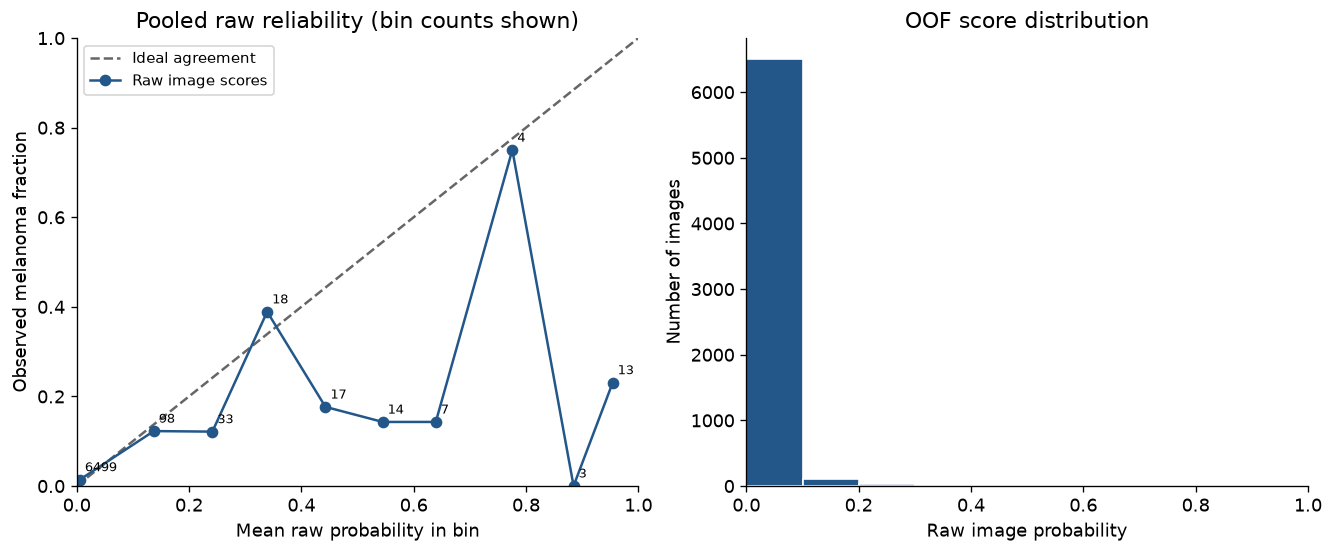

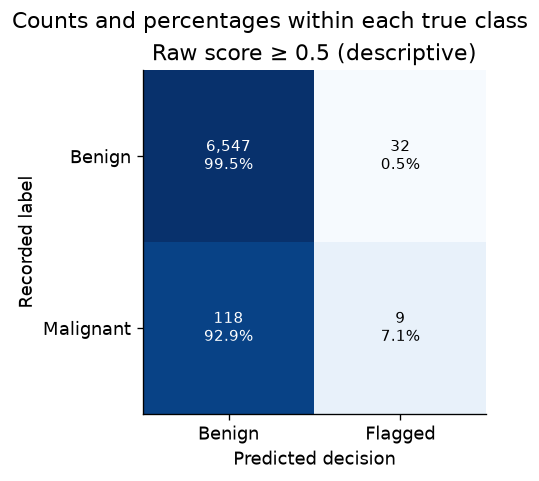

,scenario,TN,FP,FN,TP,recall,precision,specificity,flagged_images
0,Raw score ≥ 0.5 (descriptive),6547,32,118,9,0.070866,0.219512,0.995136,41


In [22]:
image_docs.raw_outer_reliability(raw, finish_figure)

### Optional training-only calibration and the 80%-recall scenario

This separate stage has its own run directory. Its clean artifacts are read only after the raw
five-fold evaluation verifies. Three fresh fixed-duration inner refits per
outer fold were the separate training-only calibration protocol; opening this
notebook starts none of those fits. Each uses that outer pool's already
selected recipe and median epoch duration. Its training-only OOF predictions
fit a logistic calibration map on logits (`C=1`) and choose the highest cutoff
reaching 80% malignant recall on those training predictions. A failed or
non-positive-slope map is recorded and leaves the separate calibration stage
incomplete; the raw report remains available. Complete frozen maps and cutoffs
are then applied to the unchanged raw outer predictions.

All five calibration folds must finish and their clean receipts must verify
before the comparisons below appear; the status table reports actual completion.
Calibration is assessed through held-out log loss, Brier and reliability.
Positive-slope maps preserve ordering within a fold, so fold AP/ROC-AUC should
stay the same; numerical clipping or ties require inspection if they change.
Pooled AP may change when the five folds' score scales change.

The 80% recall value is a **training selection target**, not a promise about
actual outer recall or a clinically validated target. Report the actual held-out
recall, precision, F1, specificity and confusion counts. Calibration maps and
cutoffs remain fixed in the reported conditional bootstrap intervals. The raw
five-fold status and matched metadata comparison remain unchanged.


,fold,n_images,n_patients,n_positive,prevalence,average_precision,roc_auc,log_loss,brier,model
0,0,1344,84,24,0.017857,0.152537,0.854419,0.095513,0.022482,raw
1,1,1366,84,26,0.019034,0.148876,0.839179,0.090245,0.019154,raw
2,2,1328,87,26,0.019578,0.148730,0.864823,0.082345,0.018674,raw
3,3,1371,82,25,0.018235,0.057262,0.757266,0.138206,0.018364,raw
4,4,1297,85,26,0.020046,0.150444,0.838316,0.089270,0.019511,raw
5,0,1344,84,24,0.017857,0.152537,0.854419,0.090409,0.017738,calibrated
6,1,1366,84,26,0.019034,0.148876,0.839179,0.078001,0.017527,calibrated
7,2,1328,87,26,0.019578,0.148730,0.864823,0.076806,0.018044,calibrated
8,3,1371,82,25,0.018235,0.057262,0.757266,0.089645,0.017793,calibrated
9,4,1297,85,26,0.020046,0.150444,0.838316,0.087645,0.018813,calibrated


,fold,raw_average_precision,calibrated_average_precision,ap_difference,raw_roc_auc,calibrated_roc_auc,ap_invariant,roc_auc_invariant,changed_training_selected_decisions
0,0,0.152537,0.152537,0.000000e+00,0.854419,0.854419,True,True,0
1,1,0.148876,0.148876,0.000000e+00,0.839179,0.839179,True,True,0
2,2,0.148730,0.148730,0.000000e+00,0.864823,0.864823,True,True,0
3,3,0.057262,0.057262,-6.938894e-18,0.757266,0.757266,True,True,0
4,4,0.150444,0.150444,0.000000e+00,0.838316,0.838316,True,True,0


,fold,model,n_images,n_patients,n_positive,training_target_recall,threshold,threshold_scope,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction,recall,f1
0,0,raw,1344,84,24,0.8,0.000056,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
1,0,calibrated,1344,84,24,0.8,0.016348,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
2,1,raw,1366,84,26,0.8,0.002104,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
3,1,calibrated,1366,84,26,0.8,0.017208,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
4,2,raw,1328,87,26,0.8,0.006221,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
5,2,calibrated,1328,87,26,0.8,0.015723,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
6,3,raw,1371,82,25,0.8,0.001956,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
7,3,calibrated,1371,82,25,0.8,0.018041,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
8,4,raw,1297,85,26,0.8,0.000228,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243
9,4,calibrated,1297,85,26,0.8,0.015263,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243


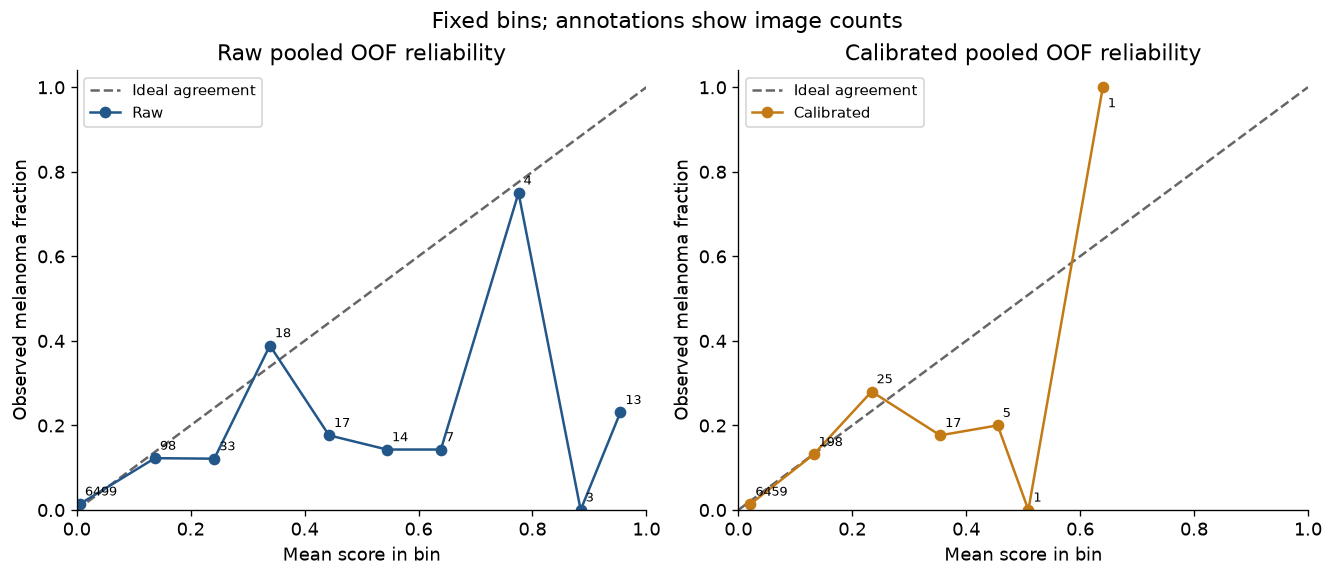

,bin,lower,upper,n_images,n_positive,mean_probability,observed_prevalence,model
0,0,0.0,0.1,6499,92,0.005610,0.014156,Raw
1,1,0.1,0.2,98,12,0.137267,0.122449,Raw
2,2,0.2,0.3,33,4,0.241452,0.121212,Raw
3,3,0.3,0.4,18,7,0.339054,0.388889,Raw
4,4,0.4,0.5,17,3,0.442833,0.176471,Raw
5,5,0.5,0.6,14,2,0.544697,0.142857,Raw
6,6,0.6,0.7,7,1,0.639248,0.142857,Raw
7,7,0.7,0.8,4,3,0.775557,0.750000,Raw
8,8,0.8,0.9,3,0,0.884586,0.000000,Raw
9,9,0.9,1.0,13,3,0.954277,0.230769,Raw


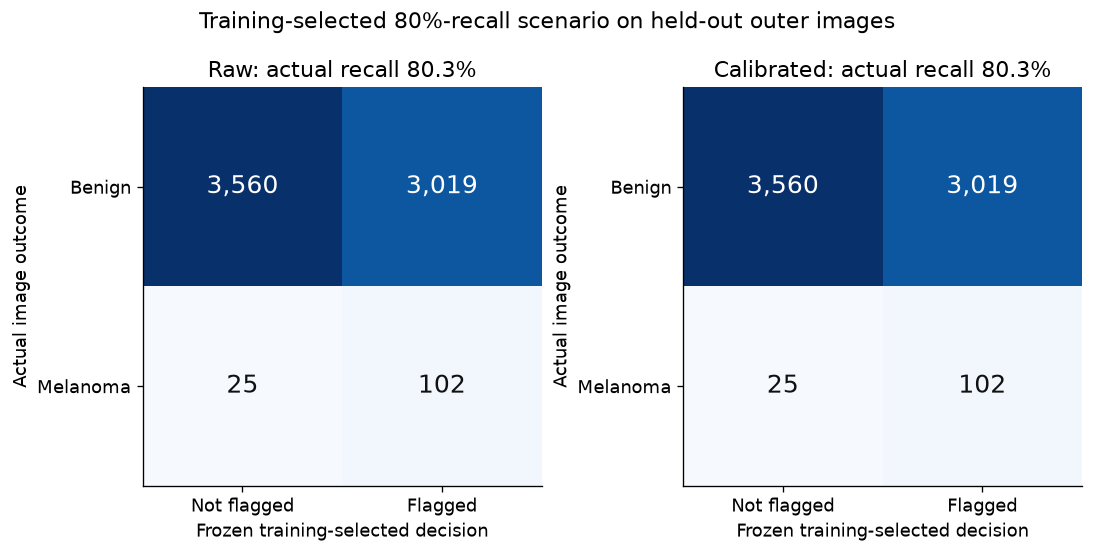

A monotonic map preserves within-fold ranking. Different fold-specific maps can change pooled ordering. Calibration is assessed with log loss, Brier and reliability; the academic training-only 80%-recall rule does not guarantee 80% recall on held-out patients.

In [23]:
image_docs.calibration_figures(calibration, finish_figure)

In [24]:
if calibration['complete']:
    display(calibration['ranking_invariance'])
    display(calibration['scenario_by_fold'])

,fold,raw_average_precision,calibrated_average_precision,ap_difference,raw_roc_auc,calibrated_roc_auc,ap_invariant,roc_auc_invariant,changed_training_selected_decisions
0,0,0.152537,0.152537,0.000000e+00,0.854419,0.854419,True,True,0
1,1,0.148876,0.148876,0.000000e+00,0.839179,0.839179,True,True,0
2,2,0.148730,0.148730,0.000000e+00,0.864823,0.864823,True,True,0
3,3,0.057262,0.057262,-6.938894e-18,0.757266,0.757266,True,True,0
4,4,0.150444,0.150444,0.000000e+00,0.838316,0.838316,True,True,0


,fold,model,n_images,n_patients,n_positive,training_target_recall,threshold,threshold_scope,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction,recall,f1
0,0,raw,1344,84,24,0.8,0.000056,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
1,0,calibrated,1344,84,24,0.8,0.016348,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
2,1,raw,1366,84,26,0.8,0.002104,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
3,1,calibrated,1366,84,26,0.8,0.017208,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
4,2,raw,1328,87,26,0.8,0.006221,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
5,2,calibrated,1328,87,26,0.8,0.015723,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
6,3,raw,1371,82,25,0.8,0.001956,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
7,3,calibrated,1371,82,25,0.8,0.018041,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
8,4,raw,1297,85,26,0.8,0.000228,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243
9,4,calibrated,1297,85,26,0.8,0.015263,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243


### Matched metadata comparison

When present, metadata scores come from the clean hash-recorded OOF
prediction bundle with verified retained identities. The image-minus-metadata
interval uses the **same patient draw** for both models. Positive AP or ROC-AUC
differences favour the image model; negative log-loss or Brier differences
favour it. These are paired development comparisons after prior diagnostics.


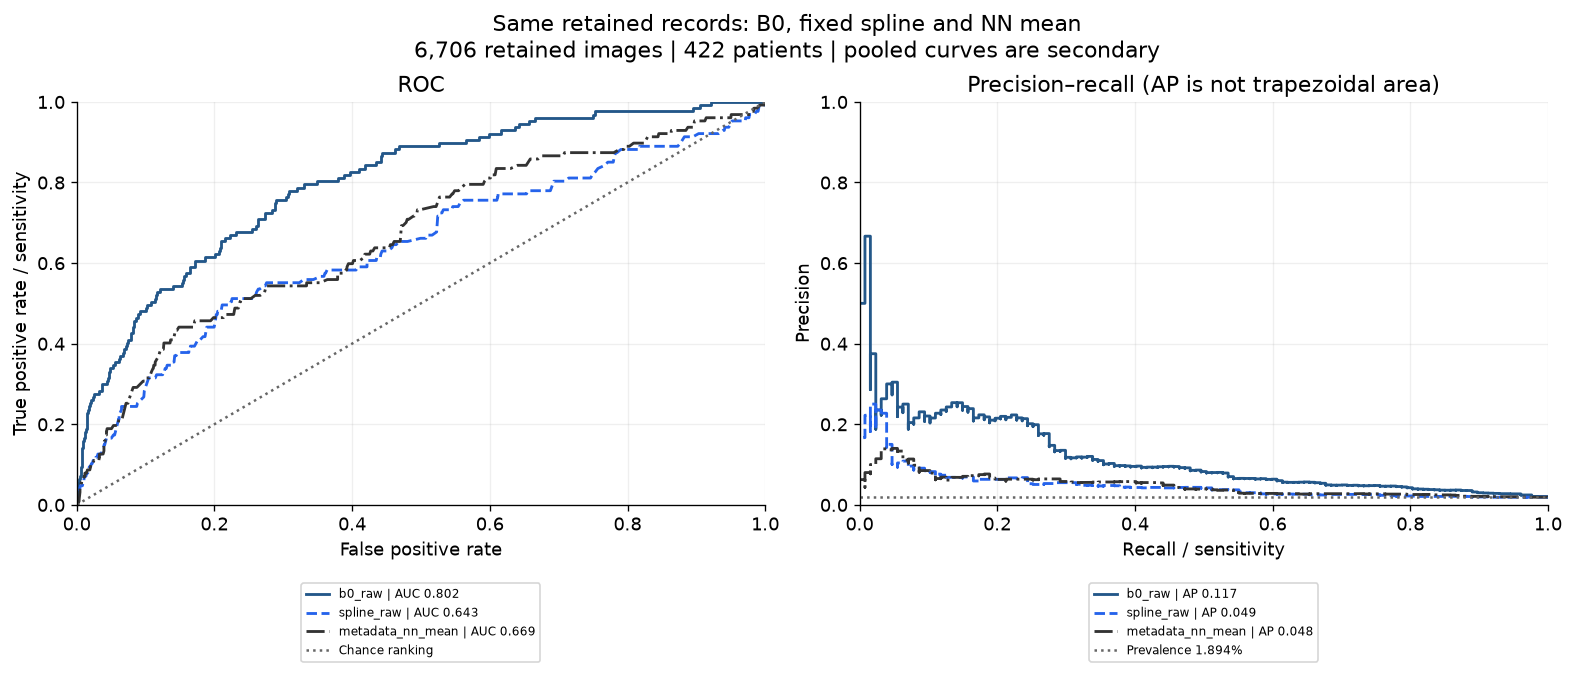

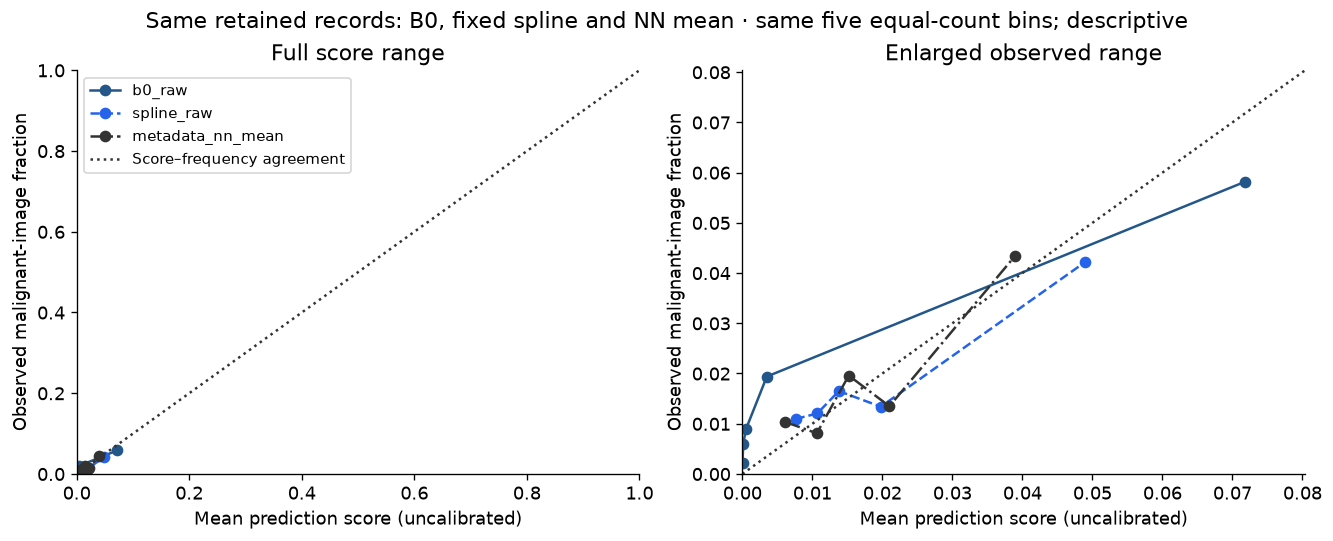

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,model
0,1,1342,3,0.000017,0.002235,2.590740e-09,0.000050,164,b0_raw
1,2,1341,8,0.000110,0.005966,4.980170e-05,0.000201,217,b0_raw
2,3,1341,12,0.000517,0.008949,2.014816e-04,0.001118,286,b0_raw
3,4,1341,26,0.003487,0.019389,1.118944e-03,0.007783,329,b0_raw
4,5,1341,78,0.071764,0.058166,7.784358e-03,0.991087,309,b0_raw
5,1,1371,15,0.007594,0.010941,2.805209e-03,0.009150,121,spline_raw
6,2,1329,16,0.010693,0.012039,9.175152e-03,0.011864,162,spline_raw
7,3,1334,22,0.013772,0.016492,1.193646e-02,0.016044,187,spline_raw
8,4,1344,18,0.019765,0.013393,1.617859e-02,0.025073,203,spline_raw
9,5,1328,56,0.048934,0.042169,2.537785e-02,0.421284,198,spline_raw


In [25]:
image_docs.matched_comparator_figures(score_bundle(), finish_figure)

## Takeaways

Use mean-fold AP and its conditional patient interval together with fold
variation when assessing this image model. Pooled AP, raw-score reliability and
the declared-cutoff confusion counts answer complementary questions. Preserve
the development caveat when presenting these results; the reserved test is the
remaining independent assessment after all decisions are frozen.


In [26]:
image_docs.image_takeaways(raw, comparison_table())

**Executed clean B0 result:** mean outer-fold AP **0.1316** and mean ROC-AUC **0.8308**. AP ranges from **0.057 to 0.153** across the five retained patient groups. The observed fold spread is descriptive variability, not a confidence interval. These values replace the historical pilot findings; they remain development evidence after earlier exploration.

,population,model,aggregation,fold,weighting,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,role
7,clean,b0_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.131570,0.830801,0.099116,0.019637,predeclared
10,clean,metadata_nn_mean,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.059570,0.676694,0.090169,0.018382,predeclared
17,clean,spline_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.064842,0.655631,0.091006,0.018422,predeclared


## Combined evaluation extensions

These additional checks document the deduplicated comparison beyond the original templates. Their primary summaries use unweighted mean-fold AP and ROC-AUC; pooled figures, patient weighting and subgroup comparisons remain secondary. Completion is read from verified experiment artifacts, not from a stale controller queue or historical pilot result.

### 1. Establish completion and provenance before comparing

A trained checkpoint alone is not a verified evaluation. Require dataset identity, matching image/patient/label/fold coverage, saved artifact fingerprints and reporting completion. Incomplete image stages remain pending and do not enter the final image-versus-metadata conclusion.

In [27]:
from melanoma_detection.dedup_notebook_evaluation import COMPARISON_COLORS, COMPARISON_LINES, METRIC_LABELS
from melanoma_detection.dedup_notebook_metadata import LABELS
COMPARISON_LABELS = {**LABELS, "b0_raw": "Raw B0"}
evaluation = latest_evaluation(ROOT)
bundle = score_bundle()
expected = bundle["expected"]
scores = bundle["scores"]
display(pd.DataFrame([evaluation.get("stages", {})]))
display(pd.DataFrame([{"evaluation_status":evaluation["status"], "matching_images":len(expected),
    "patients":expected.patient_id.nunique(),"malignant_images":int(expected.target.sum()),
    "dataset_manifest_sha256":dataset_identity["dataset_manifest_sha256"]}]))
assert len(expected) == 6706 and expected.image_id.is_unique
assert set(expected.image_id) == set(data.image_name)
for name, values in scores.items():
    assert len(values) == len(expected) and np.isfinite(values).all()
display(Markdown(evaluation.get("image_conclusion", "Clean comparison pending.")))

,metadata_core,metadata_suite,image_raw,image_calibration
0,complete,complete,complete,complete


,evaluation_status,matching_images,patients,malignant_images,dataset_manifest_sha256
0,complete,6706,422,127,9f7f0f3bfc436b90372c76c6925fbc12cdd8a413556d7e...


Clean B0 has the highest mean-fold AP among the three predeclared comparators (0.1316). Both paired AP intervals exclude zero in its favour. This supports reviewing B0 as the ranking choice on these development patients. Secondary tuned models and inner pilots do not automatically change the selected procedure. No reserved-test or clinical claim follows.

### 2. State the estimands and predeclared comparisons

Primary ranking results are unweighted mean-fold AP and ROC-AUC: compute each held-out fold's metric, then average the five numbers. Pooled metrics rank all OOF rows together and can be affected by differences in score scales across folds, so they are secondary. AP summarizes precision as recall increases; ROC-AUC summarizes ranking across both classes. Accuracy is unsuitable for this rare-positive target. Predeclared contrasts are B0 minus fixed spline, B0 minus the prescribed NN mean, and NN mean minus spline.

,population,model,aggregation,fold,weighting,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,role
0,clean,ablation_age,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.045769,0.655074,0.091558,0.018454,secondary
1,clean,ablation_age_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.063622,0.666526,0.090723,0.018423,secondary
2,clean,ablation_all_features,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.064842,0.655631,0.091006,0.018422,secondary
3,clean,ablation_sex,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.021911,0.551898,0.093819,0.018587,secondary
4,clean,ablation_sex_age,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.045641,0.631247,0.091890,0.018461,secondary
5,clean,ablation_sex_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.033656,0.586431,0.092613,0.018524,secondary
6,clean,ablation_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.029049,0.562516,0.092716,0.018533,secondary
7,clean,b0_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.131570,0.830801,0.099116,0.019637,predeclared
8,clean,categorical_logistic,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.056685,0.596946,0.092438,0.018490,secondary
9,clean,dummy,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.018950,0.500000,0.093934,0.018591,secondary


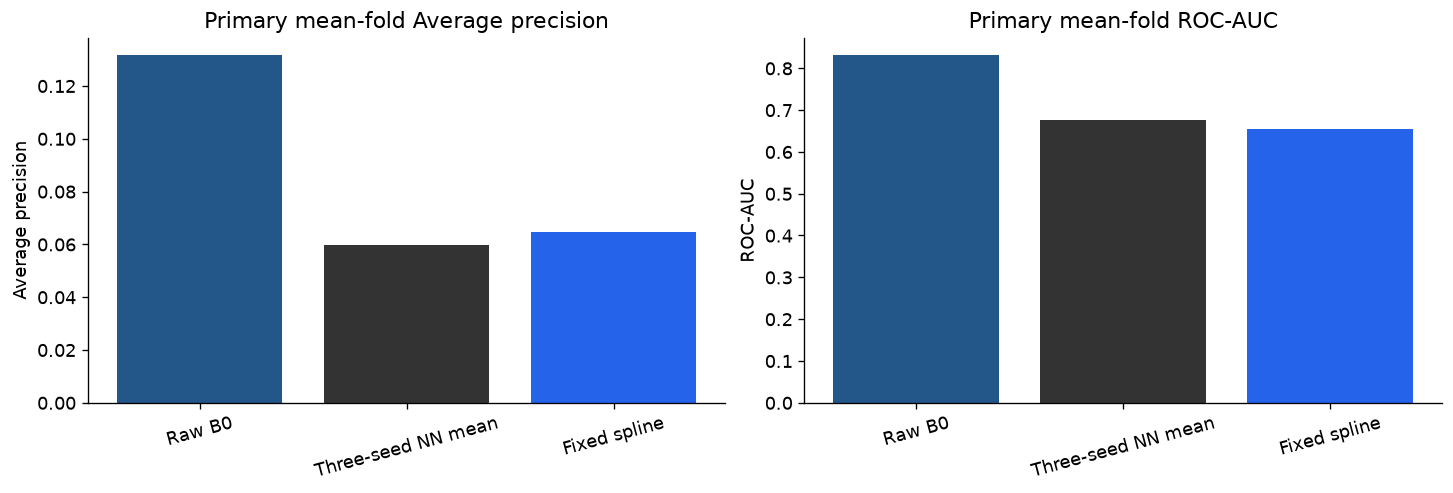

In [28]:
table = comparison_table()
display(table)
core_names=["b0_raw","spline_raw","metadata_nn_mean"]
core=table.loc[table.model.isin(core_names)]
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
for ax,metric,label in [(axes[0],"average_precision","Average precision"),(axes[1],"roc_auc","ROC-AUC")]:
    ax.bar([COMPARISON_LABELS[name] for name in core.model],core[metric],color=[COMPARISON_COLORS[name] for name in core.model])
    ax.set(title="Primary mean-fold "+label,ylabel=label); ax.tick_params(axis="x",rotation=15)
finish_figure(fig,"core_mean_fold_ap_auc")
if "b0_raw" not in scores: display(Markdown("**Pending:** B0 has not supplied all five verified outer predictions; current bars show metadata only."))

### 3. Read fold variation and pooled curves

Replicate the original fold tables, ROC and precision–recall views on matching clean records. Curves here pool OOF scores and are secondary illustrations, while mean-fold metrics remain primary. A dashed prevalence line provides the constant-score reference for precision–recall. Fold variability can be large when only 24–26 malignant images occur in a group.

,model,fold,n_images,n_malignant_images,n_malignant_patients,average_precision,roc_auc
0,metadata_nn_mean,0,1344.0,24.0,17.0,0.053464,0.761064
2,spline_raw,0,1344.0,24.0,17.0,0.066199,0.794397
40,b0_raw,0,1344.0,24.0,17.0,0.152537,0.854419
42,metadata_nn_mean,1,1366.0,26.0,15.0,0.057538,0.655066
44,spline_raw,1,1366.0,26.0,15.0,0.046026,0.558797
82,b0_raw,1,1366.0,26.0,15.0,0.148876,0.839179
84,metadata_nn_mean,2,1328.0,26.0,21.0,0.042187,0.668011
86,spline_raw,2,1328.0,26.0,21.0,0.037312,0.631130
124,b0_raw,2,1328.0,26.0,21.0,0.148730,0.864823
126,metadata_nn_mean,3,1371.0,25.0,18.0,0.059744,0.689421


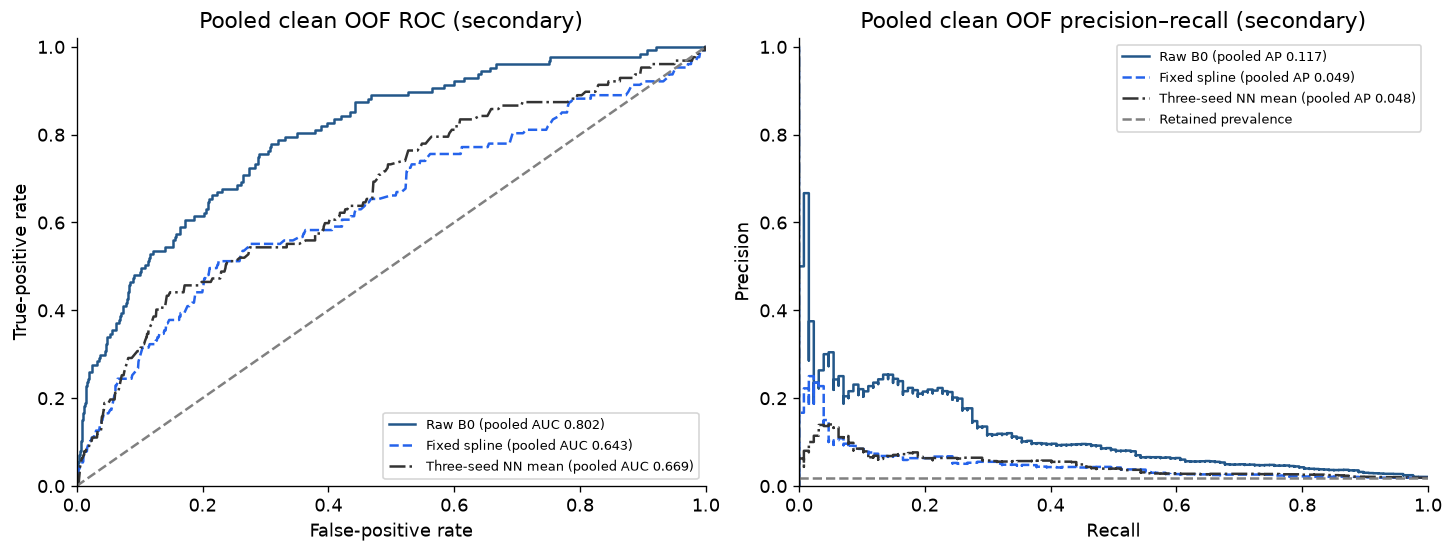

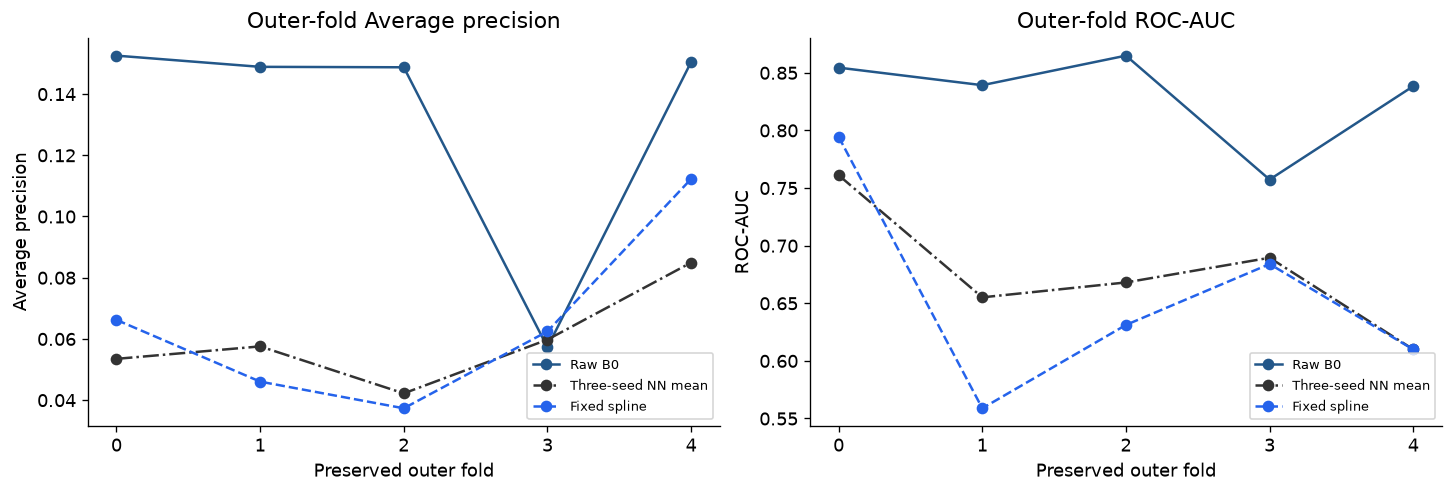

In [29]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, roc_auc_score
directory=project_path(ROOT,evaluation["output_directory"])
metrics=pd.read_csv(directory/"metrics.csv")
by_fold=metrics.loc[metrics.model.isin(core_names)&metrics.aggregation.eq("by_fold")&metrics.weighting.eq("image")]
display(by_fold[["model","fold","n_images","n_malignant_images","n_malignant_patients","average_precision","roc_auc"]])
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
for name in core_names:
    if name not in scores: continue
    fpr,tpr,_=roc_curve(expected.target,scores[name]); precision,recall,_=precision_recall_curve(expected.target,scores[name])
    axes[0].plot(fpr,tpr,color=COMPARISON_COLORS[name],linestyle=COMPARISON_LINES[name],label=f"{COMPARISON_LABELS[name]} (pooled AUC {roc_auc_score(expected.target,scores[name]):.3f})")
    axes[1].step(recall,precision,where="post",color=COMPARISON_COLORS[name],linestyle=COMPARISON_LINES[name],label=f"{COMPARISON_LABELS[name]} (pooled AP {average_precision_score(expected.target,scores[name]):.3f})")
axes[0].plot([0,1],[0,1],"--",color="grey"); axes[1].axhline(expected.target.mean(),ls="--",color="grey",label="Retained prevalence")
axes[0].set(title="Pooled clean OOF ROC (secondary)",xlabel="False-positive rate",ylabel="True-positive rate")
axes[1].set(title="Pooled clean OOF precision–recall (secondary)",xlabel="Recall",ylabel="Precision")
for ax in axes: ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend(fontsize=8)
finish_figure(fig,"core_roc_precision_recall")
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
for name,rows in by_fold.groupby("model"):
    for ax,metric in zip(axes,["average_precision","roc_auc"]): ax.plot(rows.fold.astype(int),rows[metric],marker="o",color=COMPARISON_COLORS[name],linestyle=COMPARISON_LINES[name],label=COMPARISON_LABELS[name])
for ax,metric in zip(axes,["average_precision","roc_auc"]): ax.set(title="Outer-fold "+METRIC_LABELS[metric],xlabel="Preserved outer fold",ylabel=METRIC_LABELS[metric],xticks=range(5)); ax.legend(fontsize=8)
finish_figure(fig,"core_fold_variation")

### 4. Use paired whole-patient intervals

Sample patients with replacement within each outer fold for 2,000 draws, seed 42, and copy all their retained images together. Every model receives the same patient multiplicities on a draw. For a difference, compute A minus B on each draw, then use its 2.5th and 97.5th percentiles. Record invalid single-class draws. Intervals condition on these saved models and omit training/selection uncertainty; they do not establish clinical benefit.

,comparison,aggregation,metric,difference,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed,role
0,b0_raw minus metadata_nn_mean,mean_fold,average_precision,0.071999,0.022864,0.148646,2000,2000,0,42,predeclared development comparison
1,b0_raw minus metadata_nn_mean,mean_fold,roc_auc,0.154107,0.092697,0.207803,2000,2000,0,42,predeclared development comparison
8,b0_raw minus spline_raw,mean_fold,average_precision,0.066728,0.010437,0.145808,2000,2000,0,42,predeclared development comparison
9,b0_raw minus spline_raw,mean_fold,roc_auc,0.175170,0.105800,0.232184,2000,2000,0,42,predeclared development comparison
16,metadata_nn_mean minus spline_raw,mean_fold,average_precision,-0.005271,-0.025522,0.007595,2000,2000,0,42,predeclared development comparison
17,metadata_nn_mean minus spline_raw,mean_fold,roc_auc,0.021063,-0.005631,0.041326,2000,2000,0,42,predeclared development comparison


,model,aggregation,metric,estimate,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed,interval
0,metadata_nn_mean,mean_fold,average_precision,0.059570,0.044039,0.105900,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
1,metadata_nn_mean,mean_fold,roc_auc,0.676694,0.614121,0.735503,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
8,spline_raw,mean_fold,average_precision,0.064842,0.045574,0.115039,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
9,spline_raw,mean_fold,roc_auc,0.655631,0.593995,0.720417,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
16,b0_raw,mean_fold,average_precision,0.131570,0.094697,0.218854,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
17,b0_raw,mean_fold,roc_auc,0.830801,0.787076,0.865113,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."


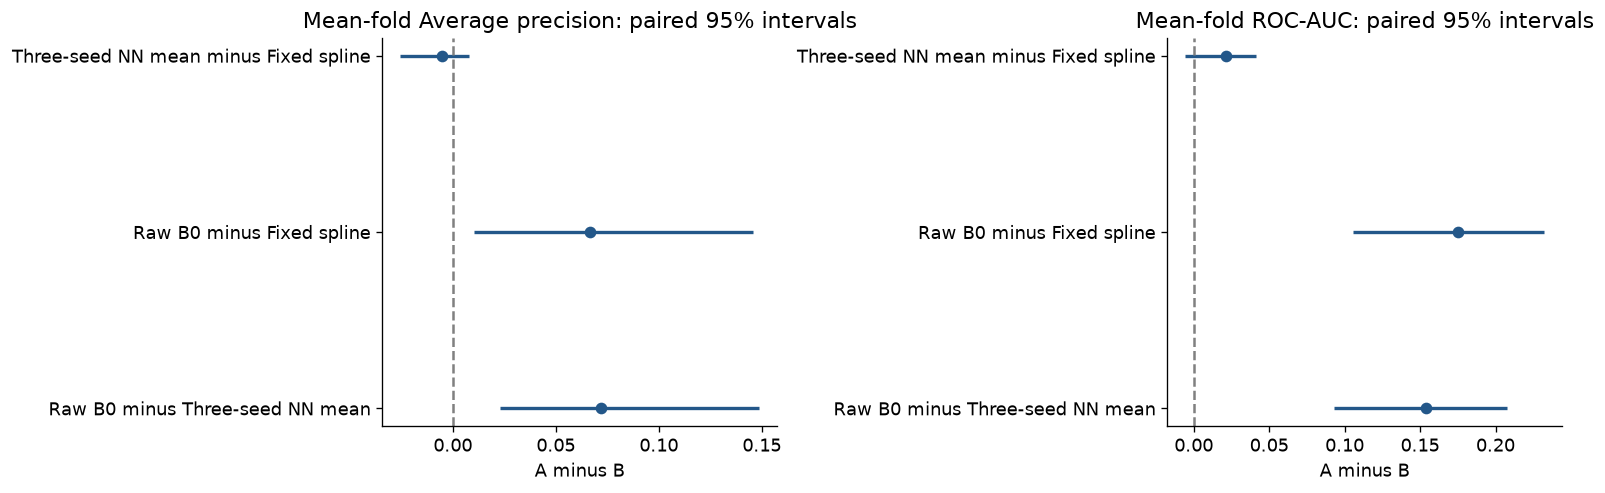

In [30]:
intervals=pd.read_csv(directory/"bootstrap_intervals.csv")
comparisons=pd.read_csv(directory/"paired_comparisons.csv")
primary=comparisons.loc[comparisons.aggregation.eq("mean_fold")&comparisons.metric.isin(["average_precision","roc_auc"])]
display(primary)
display(intervals.loc[intervals.aggregation.eq("mean_fold")&intervals.metric.isin(["average_precision","roc_auc"])])
fig,axes=plt.subplots(1,2,figsize=(13,4),layout="constrained")
for ax,metric in zip(axes,["average_precision","roc_auc"]):
    selected=primary.loc[primary.metric.eq(metric)].reset_index(drop=True)
    pos=np.arange(len(selected))
    ax.hlines(pos,selected.ci_lower,selected.ci_upper,color="#235789",linewidth=2)
    ax.scatter(selected.difference,pos,color="#235789"); ax.axvline(0,color="grey",ls="--")
    comparison_labels = selected.comparison.copy()
    for name in core_names:
        comparison_labels = comparison_labels.str.replace(name, COMPARISON_LABELS[name], regex=False)
    ax.set(yticks=pos,yticklabels=comparison_labels,xlabel="A minus B",title="Mean-fold "+METRIC_LABELS[metric]+": paired 95% intervals")
finish_figure(fig,"core_paired_patient_intervals")

### 5. Separate patient weighting from patient-level prediction

As a secondary diagnostic, give each image weight 1 divided by that patient's retained image count. This makes total image weight equal across patients while keeping the image-level target. It does not turn an image score into a patient diagnosis. Compare with conventional image-weighted results on the same records; never select a model merely because one weighting is favourable.

,model,weighting,average_precision,roc_auc
266,b0_raw,equal_patient,0.192361,0.792627
267,b0_raw,image,0.131570,0.830801
272,metadata_nn_mean,equal_patient,0.115317,0.720950
273,metadata_nn_mean,image,0.059570,0.676694
286,spline_raw,equal_patient,0.127097,0.706556
287,spline_raw,image,0.064842,0.655631


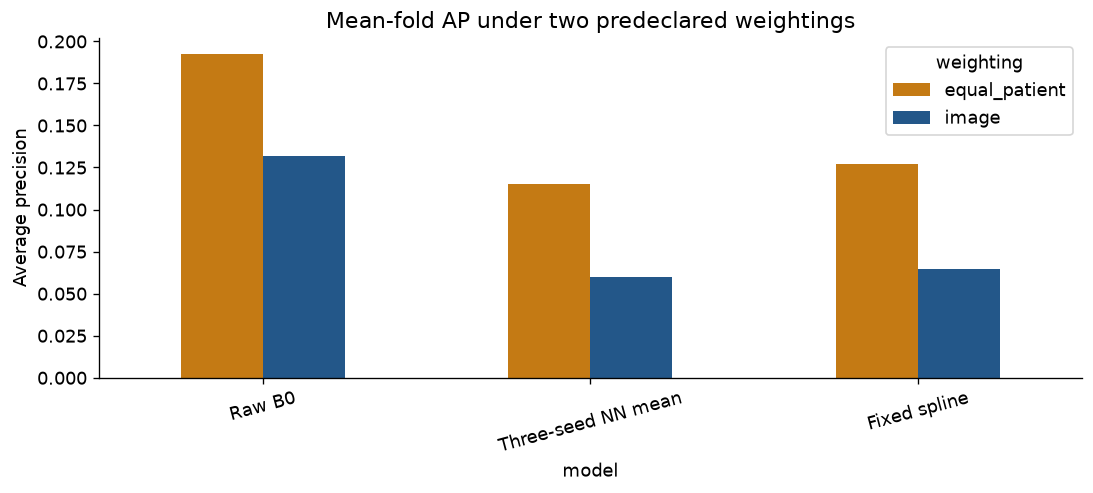

In [31]:
weighted=metrics.loc[metrics.model.isin(core_names)&metrics.aggregation.eq("mean_fold")]
display(weighted[["model","weighting","average_precision","roc_auc"]])
pivot=weighted.pivot(index="model",columns="weighting",values="average_precision")
fig,ax=plt.subplots(figsize=(9,4),layout="constrained")
pivot.rename(index=COMPARISON_LABELS).plot.bar(ax=ax,color=["#C47A14","#235789"],rot=15)
ax.set(title="Mean-fold AP under two predeclared weightings",ylabel="Average precision")
finish_figure(fig,"equal_patient_weight_ap")

### 6. Assess probabilities and training-only decision workload

Ranking, calibration and decisions answer different questions. Brier and log loss assess probability quality; calibration maps and recall cutoffs must be learned inside each outer-training pool. Combine the resulting outer decisions without searching for a better cutoff on the reported OOF labels. Read recall beside precision and the number of images flagged. A fixed 0.5 cutoff is a diagnostic rather than the main recall scenario.

,model,log_loss,brier
267,b0_raw,0.099116,0.019637
273,metadata_nn_mean,0.090169,0.018382
285,spline_calibrated,0.090830,0.018410
287,spline_raw,0.091006,0.018422


,model,score_scale,fold,n_images,n_patients,malignant_images,malignant_patients,n_flagged,cutoff_minimum,cutoff_maximum,...,brier,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction,cutoff_source
0,fixed_spline,p_spline_raw,0,1344,84,24,17,1123,0.010618,0.010618,...,0.017236,24,1099,221,0,1.000000,0.167424,0.021371,0.835565,training-only OOF; academic target recall 0.8
1,fixed_spline,p_spline_raw,1,1366,84,26,15,819,0.011326,0.011326,...,0.018746,17,802,538,9,0.653846,0.401493,0.020757,0.599561,training-only OOF; academic target recall 0.8
2,fixed_spline,p_spline_raw,2,1328,87,26,21,853,0.009737,0.009737,...,0.019201,21,832,470,5,0.807692,0.360983,0.024619,0.642319,training-only OOF; academic target recall 0.8
3,fixed_spline,p_spline_raw,3,1371,82,25,18,1129,0.010137,0.010137,...,0.017571,22,1107,239,3,0.880000,0.177563,0.019486,0.823487,training-only OOF; academic target recall 0.8
4,fixed_spline,p_spline_raw,4,1297,85,26,17,673,0.011971,0.011971,...,0.019355,18,655,616,8,0.692308,0.484658,0.026746,0.518890,training-only OOF; academic target recall 0.8
5,fixed_spline,p_spline_raw,pooled,6706,422,127,88,4597,0.009737,0.011971,...,0.018411,102,4495,2084,25,0.803150,0.316765,0.022188,0.685506,training-only OOF; academic target recall 0.8
6,fixed_spline,p_spline_calibrated,0,1344,84,24,17,1123,0.013546,0.013546,...,0.017272,24,1099,221,0,1.000000,0.167424,0.021371,0.835565,training-only OOF; academic target recall 0.8
7,fixed_spline,p_spline_calibrated,1,1366,84,26,15,819,0.012907,0.012907,...,0.018589,17,802,538,9,0.653846,0.401493,0.020757,0.599561,training-only OOF; academic target recall 0.8
8,fixed_spline,p_spline_calibrated,2,1328,87,26,21,853,0.011535,0.011535,...,0.019103,21,832,470,5,0.807692,0.360983,0.024619,0.642319,training-only OOF; academic target recall 0.8
9,fixed_spline,p_spline_calibrated,3,1371,82,25,18,1129,0.011808,0.011808,...,0.017630,22,1107,239,3,0.880000,0.177563,0.019486,0.823487,training-only OOF; academic target recall 0.8


,model,cutoff,role,n_flagged,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,metadata_nn_mean,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
1,spline_raw,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
2,nn_seed_42,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
3,nn_seed_142,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
4,nn_seed_242,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
5,dummy,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
6,categorical_logistic,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
7,random_forest,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
8,xgboost,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
9,ablation_sex,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0


Showing 12 of 21 rows; the complete CSV is saved.

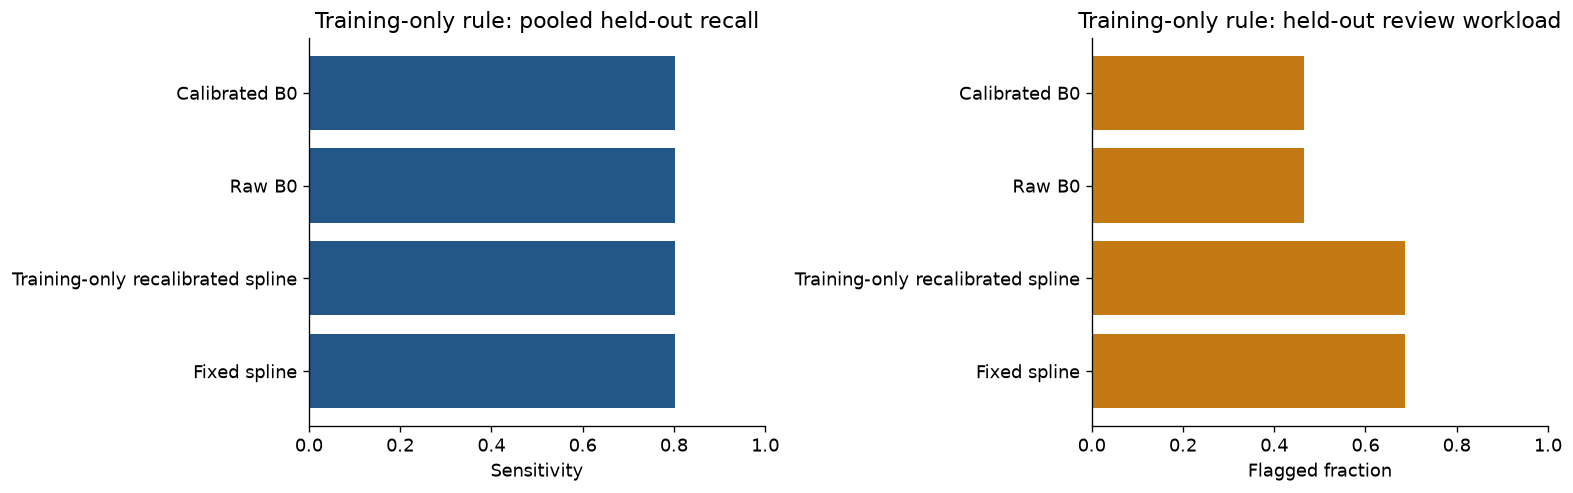

In [32]:
display(metrics.loc[metrics.aggregation.eq("mean_fold")&metrics.weighting.eq("image")&metrics.model.isin(
    ["b0_raw","spline_raw","metadata_nn_mean","spline_calibrated"]),["model","log_loss","brier"]])
decisions=pd.read_csv(directory/"training_only_cutoff_metrics.csv")
display(decisions)
show_saved_table(evaluation["output_directory"]+"/fixed_cutoff_05.csv",12)
selected=decisions.loc[decisions.fold.astype(str).eq("pooled")].copy()
if not selected.empty:
    decision_labels = {("b0", "base_probability"): "Raw B0", ("b0", "calibrated_probability"): "Calibrated B0",
        ("fixed_spline", "p_spline_raw"): LABELS["spline_raw"], ("fixed_spline", "p_spline_calibrated"): LABELS["spline_calibrated"]}
    labels = [decision_labels.get((row.model, row.score_scale), f"{row.model} / {row.score_scale}") for row in selected.itertuples()]
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout="constrained")
    axes[0].barh(labels,selected.sensitivity,color="#235789"); axes[0].set(title="Training-only rule: pooled held-out recall",xlabel="Sensitivity",xlim=(0,1))
    axes[1].barh(labels,selected.flagged_fraction,color="#C47A14"); axes[1].set(title="Training-only rule: held-out review workload",xlabel="Flagged fraction",xlim=(0,1))
    finish_figure(fig,"training_only_recall_workload")
if evaluation.get("stages",{}).get("image_calibration") != "complete": display(Markdown("**Pending:** clean image calibration and cutoffs are not yet complete. Metadata decisions above are the available training-only procedure."))

### 7. Inspect subgroup support before performance

Recreate the age, sex, anatomical-site and known/unknown-site diagnostics. Subgroup results are pooled and descriptive; no subgroup-specific rule is tuned. Display image and malignant-patient counts together. A subgroup with only two malignant patients cannot justify a strong comparative conclusion, and undefined metrics remain missing rather than zero.

,population,axis,subgroup,model,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,interpretation
0,clean,site_knownness,known,metadata_nn_mean,6511,421,125,87,0.048308,0.672219,0.091033,0.018614,descriptive pooled subgroup; support can be sp...
1,clean,site_knownness,known,spline_raw,6511,421,125,87,0.049778,0.644730,0.091876,0.018656,descriptive pooled subgroup; support can be sp...
20,clean,site_knownness,known,b0_raw,6511,421,125,87,0.115698,0.797092,0.101342,0.019942,descriptive pooled subgroup; support can be sp...
21,clean,site_knownness,unknown,metadata_nn_mean,195,53,2,2,0.011004,0.326425,0.059147,0.010234,descriptive pooled subgroup; support can be sp...
22,clean,site_knownness,unknown,spline_raw,195,53,2,2,0.077718,0.582902,0.060004,0.010247,descriptive pooled subgroup; support can be sp...
41,clean,site_knownness,unknown,b0_raw,195,53,2,2,0.375000,0.981865,0.032960,0.009337,descriptive pooled subgroup; support can be sp...
42,clean,anatomical_site,Missing,metadata_nn_mean,195,53,2,2,0.011004,0.326425,0.059147,0.010234,descriptive pooled subgroup; support can be sp...
43,clean,anatomical_site,Missing,spline_raw,195,53,2,2,0.077718,0.582902,0.060004,0.010247,descriptive pooled subgroup; support can be sp...
62,clean,anatomical_site,Missing,b0_raw,195,53,2,2,0.375000,0.981865,0.032960,0.009337,descriptive pooled subgroup; support can be sp...
63,clean,anatomical_site,head/neck,metadata_nn_mean,393,179,21,21,0.116937,0.693740,0.198117,0.049501,descriptive pooled subgroup; support can be sp...


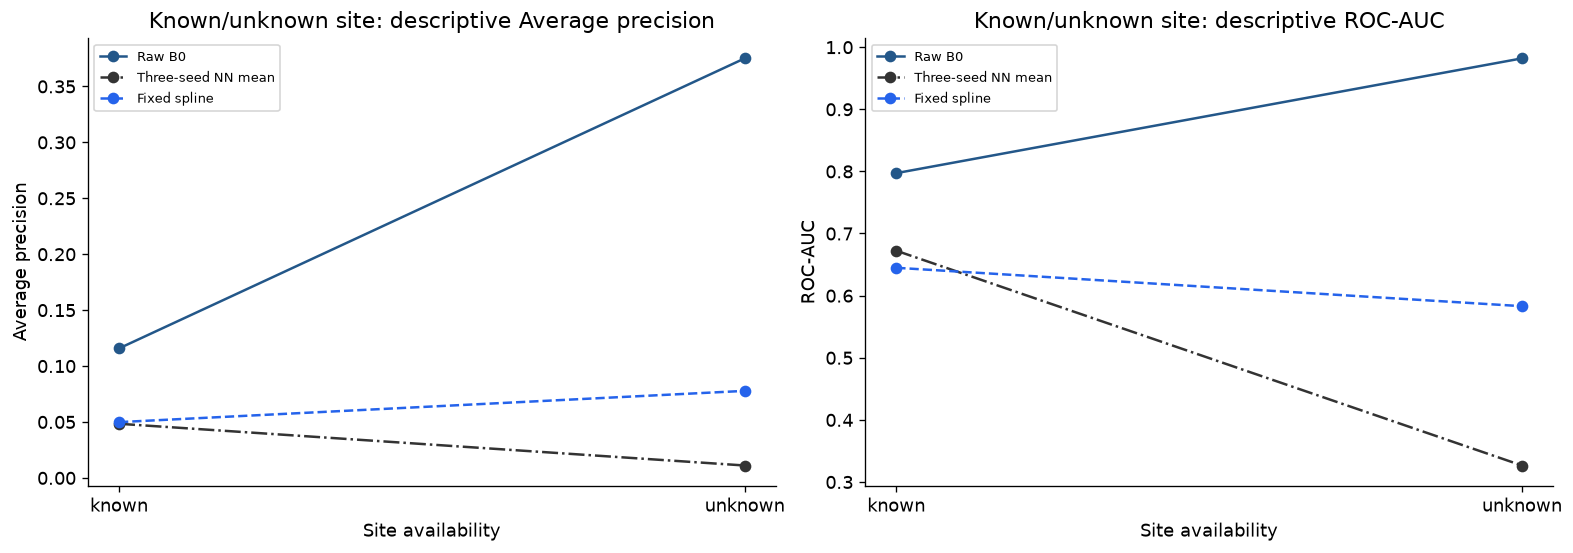

,subgroup,model,n_images,n_patients,n_malignant_images,n_malignant_patients
0,known,metadata_nn_mean,6511,421,125,87
1,known,spline_raw,6511,421,125,87
20,known,b0_raw,6511,421,125,87
21,unknown,metadata_nn_mean,195,53,2,2
22,unknown,spline_raw,195,53,2,2
41,unknown,b0_raw,195,53,2,2


In [33]:
subgroups=pd.read_csv(directory/"subgroups.csv")
selected=subgroups.loc[subgroups.model.isin(core_names)]
display(selected)
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
known=selected.loc[selected.axis.eq("site_knownness")]
for ax,metric in zip(axes,["average_precision","roc_auc"]):
    for name,rows in known.groupby("model"):
        ax.plot(rows.subgroup,rows[metric],marker="o",color=COMPARISON_COLORS[name],linestyle=COMPARISON_LINES[name],label=COMPARISON_LABELS[name])
    ax.set(title="Known/unknown site: descriptive "+METRIC_LABELS[metric],xlabel="Site availability",ylabel=METRIC_LABELS[metric]); ax.legend(fontsize=8)
finish_figure(fig,"known_unknown_site_core")
display(known[["subgroup","model","n_images","n_patients","n_malignant_images","n_malignant_patients"]])

### 8. Keep tuning, pilots and uncertainty in their proper roles

Wider metadata searches and feature ablations are secondary. B0/ConvNeXt duration pilots use selected inner validation and cannot establish a final architecture winner. MC-dropout/TTA referral describes uncertainty and error ordering from matching clean checkpoints; its averages do not automatically replace calibrated decision scores. Stronger augmentation, CLAHE, resolution changes, full challenger OOF and fusion remain deferred.

In [34]:
secondary=table.loc[~table.model.isin(core_names)]
display(secondary)
statuses=[]
for run in ["b0_duration_dedup_v1","convnext_duration_dedup_v1"]:
    _,record=pilot_report(run); statuses.append({"stage":run,"status":record.get("status","pending"),"evidence":"selected inner validation"})
uncertainty=load_uncertainty_report(ROOT)
statuses.append({"stage":"clean_uncertainty","status":uncertainty["status"],"evidence":"descriptive outer-held-out inference"})
display(pd.DataFrame(statuses))
display(Markdown("Read stages 07, 10 and 11 for their full diagnostics; these secondary observations cannot automatically change the locked primary comparison."))

,population,model,aggregation,fold,weighting,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,role
0,clean,ablation_age,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.045769,0.655074,0.091558,0.018454,secondary
1,clean,ablation_age_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.063622,0.666526,0.090723,0.018423,secondary
2,clean,ablation_all_features,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.064842,0.655631,0.091006,0.018422,secondary
3,clean,ablation_sex,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.021911,0.551898,0.093819,0.018587,secondary
4,clean,ablation_sex_age,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.045641,0.631247,0.091890,0.018461,secondary
5,clean,ablation_sex_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.033656,0.586431,0.092613,0.018524,secondary
6,clean,ablation_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.029049,0.562516,0.092716,0.018533,secondary
8,clean,categorical_logistic,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.056685,0.596946,0.092438,0.018490,secondary
9,clean,dummy,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.018950,0.500000,0.093934,0.018591,secondary
11,clean,nn_seed_142,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.058838,0.674086,0.090312,0.018381,secondary


,stage,status,evidence
0,b0_duration_dedup_v1,pending,selected inner validation
1,convnext_duration_dedup_v1,pending,selected inner validation
2,clean_uncertainty,complete,descriptive outer-held-out inference


Read stages 07, 10 and 11 for their full diagnostics; these secondary observations cannot automatically change the locked primary comparison.

### 9. Explain what duplicate sensitivity proves

The saved historical prediction analysis removes copies from evaluation only. Clean retraining also removes their training and selection weight. The main report here compares clean models; the sensitivity appendix provides a traceable check without replacing the clean experiment. The reserved test and final all-development fit remain outside this analysis.

In [35]:
display(Markdown("[Saved-prediction sensitivity appendix](../../results/dedup_v1/sensitivity/saved_oof_v2/report.md). Retained historical scores were preserved exactly; they were not averaged or selected for favourable performance."))
display(Markdown(evaluation.get("image_conclusion","Clean image comparison pending.")))
display(Markdown("**Final reporting rule:** no image-versus-metadata conclusion until the required clean OOF and calibration stages are verified. Freeze the procedure before a separate final fit and any later reserved-test evaluation."))

[Saved-prediction sensitivity appendix](../../results/dedup_v1/sensitivity/saved_oof_v2/report.md). Retained historical scores were preserved exactly; they were not averaged or selected for favourable performance.

Clean B0 has the highest mean-fold AP among the three predeclared comparators (0.1316). Both paired AP intervals exclude zero in its favour. This supports reviewing B0 as the ranking choice on these development patients. Secondary tuned models and inner pilots do not automatically change the selected procedure. No reserved-test or clinical claim follows.

**Final reporting rule:** no image-versus-metadata conclusion until the required clean OOF and calibration stages are verified. Freeze the procedure before a separate final fit and any later reserved-test evaluation.

### 10. Check reproducibility and hand off

Keep manifests, predictions, histories, calibration maps and figures under separate clean identities. The notebooks provide editable plotting code and export PNG/PDF figures, while run receipts identify the fitting implementation and saved inputs. Historical files remain byte-identical. A pending stage is explicitly incomplete, not a negative result.

In [36]:
receipt_path=ROOT / DIRECTORY / "preservation_receipt.json"
if receipt_path.exists(): display(pd.DataFrame([read_json(receipt_path)]))
display(pd.DataFrame([{"saved_evaluation_directory":evaluation["output_directory"],"stage_figure_directory":str(FIGURE_DIR),
    "training_started_by_notebook":False,"reserved_test_loaded":False}]))
display(Markdown("The clean procedure is ready for interpretation only to the extent of its verified completion. Keep original and clean outputs together when documenting limitations and provenance."))

,status,historical_artifacts_verified,historical_notebooks_verified,dataset_manifest_sha256,reserved_test_loaded
0,complete,8143,24,9f7f0f3bfc436b90372c76c6925fbc12cdd8a413556d7e...,False


,saved_evaluation_directory,stage_figure_directory,training_started_by_notebook,reserved_test_loaded
0,results/dedup_v1/clean_workflow/evaluation/f1f...,C:\Users\thoma\Documents\GitHub\ADS2002-Melano...,False,False


The clean procedure is ready for interpretation only to the extent of its verified completion. Keep original and clean outputs together when documenting limitations and provenance.